# Esquecimento do histórico: comparações pareadas entre geradores

Dentro de cada seção, duas execuções da mesma equação recebem exatamente o mesmo ruído futuro e históricos diferentes. Comparamos a distância entre saídas e entre estados de lags. O esquecimento persistente exige distância de estado ≤ 1e−6 durante os últimos 24 passos. Nos gráficos, linhas sólidas e tracejadas representam os dois históricos do par; a cor identifica a trajetória.

## Protocolo e leitura dos gráficos

Cada seção corresponde a **uma forma de inicialização**. Dentro dela comparamos AST original,
Jacobiano, Shao–Wu e Heaps. Os dois modos do Shao–Wu ocupam colunas separadas para que suas
diferenças sejam visíveis: `tanh` nos fatores e `tanh` depois do produto.

- Estudos básicos: **32 mecanismos × 3 trajetórias por condição**. Estudos cíclicos:
  **12 mecanismos × 3 trajetórias por condição**, com mais combinações de lag, período e recorte.
  Usamos um canal, pois o construtor Jacobiano atual é univariado. Horizontes: **96, 192 e 384**.
- A equação fica fixa dentro de cada banco de mecanismos. Os casos de inicialização reutilizam
  **os mesmos valores de inovação futura**, e cada trajetória recebe um fluxo local reprodutível.
  As sementes iguais entre famílias identificam amostras; cada família tem seu próprio mecanismo.
- O desvio padrão da inovação é 0,05. AST original, Shao–Wu e Heaps usam ruído gaussiano;
  Jacobiano usa ruído uniforme limitado por $\sqrt{3}\,0{,}05$. Diferenças entre famílias também
  refletem essas leis e seus diferentes vocabulários.
- Histórico inicial em $t\leq0$; primeira observação gerada em $t=1$. A saída avaliada contém
  somente os **384 valores solicitados**, sem descartar passos de aquecimento. As linhas pontilhadas
  mostram o histórico, e a faixa cinza marca os últimos $p$ valores usados pela equação.
  Os gráficos usam os mecanismos 0, 1 e 2 definidos antes dos resultados, com **as três trajetórias**.
- Explosão: valor não finito ou módulo acima de $10^6$. A primeira falha encerra a trajetória
  e permanece no denominador. Quase zero: últimos 48 valores dentro de $[-0{,}15,0{,}15]$.
  Cauda persistentemente plana: as duas janelas finais de 24 passos e seu intervalo conjunto
  de 48 passos satisfazem a tolerância 0,15 do diagnóstico existente. Platô não nulo e queda de
  amplitude usam o mesmo módulo de diagnóstico. As categorias podem se sobrepor.
- Para o Jacobiano, a inicialização precisa caber na caixa certificada $[-1,1]^p$.
  Condições incompatíveis aparecem como **não aplicáveis**, com contagem explícita de tentativas
  que não foram executadas. A inicialização gaussiana estacionária conjunta está disponível no Heaps.
- As taxas descrevem estes bancos e horizontes. As três trajetórias de um mecanismo compartilham
  sua equação. Os tempos mostrados são medições descritivas desta execução, sem repetição de benchmark.

### Como o histórico cíclico é construído

Definimos $h_k=c+A\cos(2\pi k/P)$ para $k=0,\ldots,N-1$, com
$N=P$, $N=P/2$ ou $N=P/4$. **Metade e quarto são prefixos do mesmo ciclo**: conservam o período
$P$ e o espaçamento de um passo, sem preencher o trecho removido com zeros. A amostra em $k=N-1$
é posicionada em $t=0$; o extremo direito do intervalo contínuo não é amostrado.

Nos estudos de memória, o limite $L$ vale 12, 24 ou 48 e os lags das ASTs são sorteados entre
$\lceil L/2\rceil$ e $L$. Heaps tem ordem exatamente $L$. O período vale $4L$ ou $8L$,
portanto até o quarto de ciclo fornece histórico suficiente. Cada painel informa o maior lag
efetivamente usado. O gerador consulta os últimos $p$ valores do histórico; amostras anteriores
são exibidas para tornar o recorte compreensível. Aumentar $L$ também pode alterar coeficientes
e limites calculados pelos métodos: a comparação entre bancos inclui esse efeito.

A amplitude cíclica básica é $A=0{,}5$. Comparamos $c=0$ e a soma escalar $c=0{,}5$.
A curva cosseno define a **condição inicial**; a continuação é produzida pela equação sorteada
e pelo ruído. Sua periodicidade futura é um resultado observado, não uma condição imposta.

**Código reutilizável:** [initialization.py](../../src/tsfmxai/evaluation/initialization.py)
e [initialization_study.py](../../src/tsfmxai/visualization/initialization_study.py).


Os recortes de cosseno alteram a fase e os valores presentes em t=0. Nesta execução, os três notebooks foram simulados simultaneamente; os tempos registrados refletem o compartilhamento da máquina. As métricas de qualidade usam os fluxos locais declarados.

As colunas dos painéis seguem sempre esta ordem: **AST original, Jacobiano, Shao–Wu nos fatores, Shao–Wu após o produto, Heaps**. Essa ordem também vale para colunas marcadas como não aplicáveis. Os históricos isolados usam escala linear. Nas grades de trajetórias, a escala `symlog` é linear perto de zero e logarítmica nas magnitudes maiores, preservando valores positivos e negativos.

In [1]:
from pathlib import Path
import sys, json, hashlib, subprocess, platform, importlib.metadata
from dataclasses import asdict, replace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, JSON
from threadpoolctl import threadpool_limits

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))
from tsfmxai.evaluation.initialization import (
    GROUPS, HistorySpec, InitializationStudyConfig, generator_configs,
    sample_study_mechanisms, run_history_case, run_history_pair,
)
from tsfmxai.visualization.initialization_study import (
    initialization_tables, forgetting_table, plot_history_comparison,
    plot_startup_histories, plot_case_rates, plot_pair_gaps, plot_condition_summary,
)

thread_limits = threadpool_limits(limits=1)
plt.rcParams.update({"figure.dpi": 85, "savefig.dpi": 85, "font.size": 9})
CONFIG = InitializationStudyConfig(mechanisms=32, trajectories=3, example_mechanisms=3)
SUMMARY_BLOCKS, SKIPPED_BLOCKS, DECLARATIONS = [], [], []
BANKS = {}
pd.set_option("display.max_rows", 180)
pd.set_option("display.max_columns", 24)
display(pd.Series(asdict(CONFIG), name="Configuração básica"))

def cyclic_config(lag):
    return replace(CONFIG, mechanisms=12, minimum_lag=(lag+1)//2,
                   maximum_lag=lag, heaps_fixed_order=True)

def bank(config):
    if config not in BANKS:
        BANKS[config] = {g: sample_study_mechanisms(g, config) for g in GROUPS}
    return BANKS[config]

def show_condition(block, spec, config, *, overview=True):
    mechanisms = bank(config)
    results = {g: run_history_case(g, mechanisms[g], config, spec) for g in GROUPS}
    summary, skipped = initialization_tables(results)
    if not summary.empty:
        summary.insert(0, "block", block)
        SUMMARY_BLOCKS.append(summary)
    if not skipped.empty:
        skipped.insert(0, "block", block)
        SKIPPED_BLOCKS.append(skipped)
        display(skipped.groupby(["method", "reason"], sort=False).skipped_trajectories.sum().reset_index())
    DECLARATIONS.append({"block": block, "configuration": asdict(config), "history": asdict(spec)})
    plot_startup_histories(results, block)
    plt.show()
    plot_history_comparison(results, block, config)
    plt.show()
    if not summary.empty:
        columns = ["method", "trajectories", "explosions_pct", "near_zero_pct", "persistent_flat_pct",
                   "flat_nonzero_pct", "minimum_actual_lag", "maximum_actual_lag", "mean_simulation_seconds"]
        display(summary.loc[summary.horizon == max(config.horizons), columns].round(4))
    if overview:
        plot_case_rates(results, block, config)
        plt.show()
    return results

def show_pair(block, left, right, config):
    mechanisms = bank(config)
    results = {g: run_history_pair(g, mechanisms[g], config, left, right, name=block) for g in GROUPS}
    summary = forgetting_table(results)
    if not summary.empty:
        summary.insert(0, "block", block)
        SUMMARY_BLOCKS.append(summary)
    skipped = pd.DataFrame([r for result in results.values() for r in result["skipped"]])
    if not skipped.empty:
        skipped.insert(0, "block", block)
        SKIPPED_BLOCKS.append(skipped)
        display(skipped.groupby(["method", "reason"], sort=False).skipped_trajectories.sum().reset_index())
    DECLARATIONS.append({"block": block, "configuration": asdict(config),
                         "left_history": asdict(left), "right_history": asdict(right)})
    plot_history_comparison(results, block, config)
    plt.show()
    plot_pair_gaps(results, block, config)
    plt.show()
    if not summary.empty:
        display(summary.loc[summary.horizon == max(config.horizons)].round(6))
    checks = [r["weighted_bound_passed"] for v in results.values() for r in v["rows"]
              if r["horizon"] == max(config.horizons) and r["weighted_bound_passed"] is not None]
    assert all(checks), "Falha no limite pareado do Jacobiano."
    return results

STUDY = 'forgetting'
QUESTION = 'Como cada gerador perde a influência de diferentes históricos quando a equação e o ruído futuro são idênticos?'
HYPOTHESIS = 'A contração apoia o esquecimento; o controle de amplitude do modo Shao–Wu após o produto é avaliado empiricamente para essa propriedade.'
NOTEBOOK_NAME = '3_forgetting_initial_history.ipynb'

mechanisms                                          32
trajectories                                         3
mechanism_seed                              2026102601
trajectory_seed                             2026102602
horizons                                (96, 192, 384)
innovation_std                                    0.05
explosion_limit                              1000000.0
near_zero_radius                                  0.15
tail_steps                                          48
flat_tolerance                                    0.15
window_steps                                        24
constant_value                                     0.5
uniform_radius                                     1.0
magnitude_scales        (0.0, 0.1, 0.5, 1.0, 2.0, 4.0)
forgetting_tolerance                          0.000001
forgetting_tail                                     24
minimum_lag                                          1
maximum_lag                                         12
heaps_fixe

**O que foi feito:** Definimos sementes, critérios e bancos de mecanismos reutilizados entre condições. As funções de apresentação mantêm todas as variantes lado a lado e registram cada configuração.

## 1. Constantes positiva e negativa

A única alteração dentro do par é o histórico inicial. A distância considera os últimos p valores exigidos pela equação.

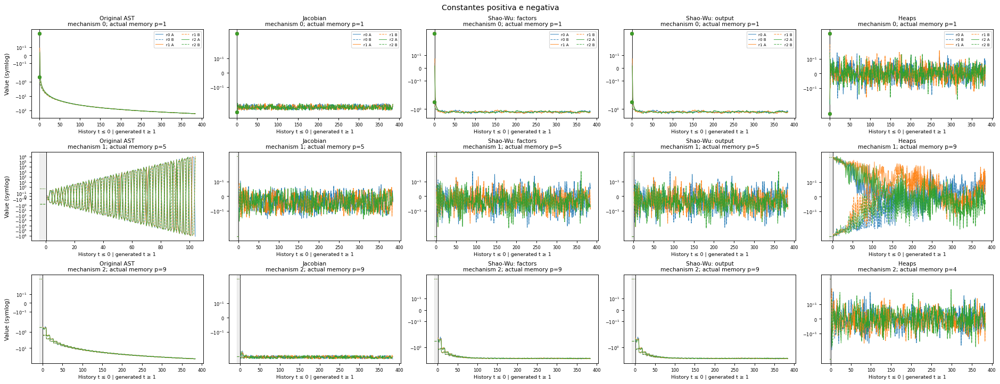

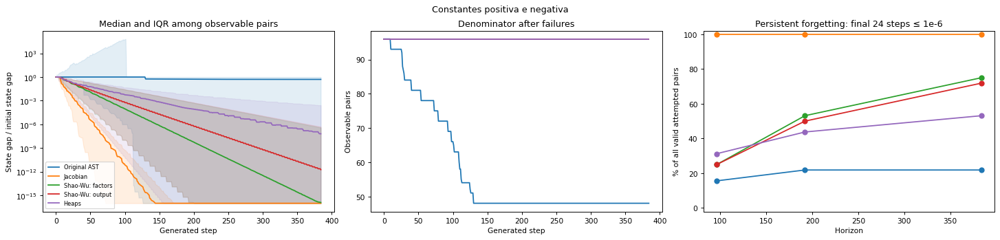

,block,method,case,horizon,mechanisms,pairs,pair_explosions,surviving_pairs,forgotten_pairs,median_final_state_gap,median_settling_step_achieved,weighted_checks,pair_explosion_pct,forgotten_pct_all_pairs,forgotten_pct_survivors
2,Constantes positiva e negativa,Original AST,Constantes positiva e negativa,384,32,96,48,48,21,0.501125,30.0,0,50.0,21.875,43.750
5,Constantes positiva e negativa,Jacobian,Constantes positiva e negativa,384,32,96,0,96,96,0.000000,56.0,96,0.0,100.000,100.000
8,Constantes positiva e negativa,Shao-Wu: factors,Constantes positiva e negativa,384,32,96,0,96,72,0.000000,102.0,0,0.0,75.000,75.000
11,Constantes positiva e negativa,Shao-Wu: output,Constantes positiva e negativa,384,32,96,0,96,69,0.000000,102.0,0,0.0,71.875,71.875
14,Constantes positiva e negativa,Heaps,Constantes positiva e negativa,384,32,96,0,96,51,0.000000,63.0,0,0.0,53.125,53.125


In [2]:
result = show_pair('Constantes positiva e negativa', HistorySpec('positive', 'constant', offset=.5), HistorySpec('negative', 'constant', offset=-.5), CONFIG)

**O que foi feito:** A grade mostra os dois caminhos de cada par. O painel seguinte compara a distância normalizada, os pares ainda observáveis e o percentual de esquecimento; falhas ficam ausentes nas distâncias e presentes no denominador das taxas.

## 2. Histórico uniforme versus zero

A única alteração dentro do par é o histórico inicial. A distância considera os últimos p valores exigidos pela equação.

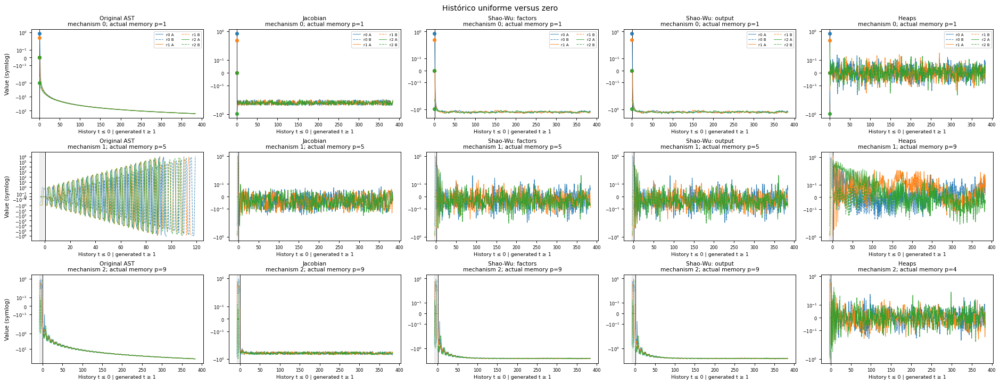

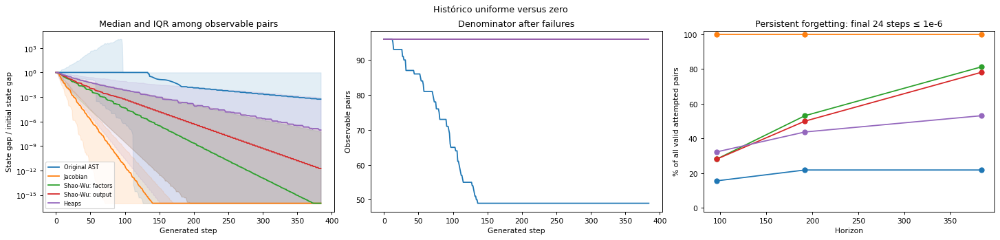

,block,method,case,horizon,mechanisms,pairs,pair_explosions,surviving_pairs,forgotten_pairs,median_final_state_gap,median_settling_step_achieved,weighted_checks,pair_explosion_pct,forgotten_pct_all_pairs,forgotten_pct_survivors
2,Histórico uniforme versus zero,Original AST,Histórico uniforme versus zero,384,32,96,47,49,21,0.000522,26.0,0,48.958333,21.875,42.857143
5,Histórico uniforme versus zero,Jacobian,Histórico uniforme versus zero,384,32,96,0,96,96,0.000000,52.0,96,0.000000,100.000,100.000000
8,Histórico uniforme versus zero,Shao-Wu: factors,Histórico uniforme versus zero,384,32,96,0,96,78,0.000000,100.5,0,0.000000,81.250,81.250000
11,Histórico uniforme versus zero,Shao-Wu: output,Histórico uniforme versus zero,384,32,96,0,96,75,0.000000,99.0,0,0.000000,78.125,78.125000
14,Histórico uniforme versus zero,Heaps,Histórico uniforme versus zero,384,32,96,0,96,51,0.000000,55.0,0,0.000000,53.125,53.125000


In [3]:
result = show_pair('Histórico uniforme versus zero', HistorySpec('uniform', 'uniform'), HistorySpec('zero', 'zero'), CONFIG)

**O que foi feito:** A grade mostra os dois caminhos de cada par. O painel seguinte compara a distância normalizada, os pares ainda observáveis e o percentual de esquecimento; falhas ficam ausentes nas distâncias e presentes no denominador das taxas.

## 3. Histórico estacionário versus zero

A única alteração dentro do par é o histórico inicial. A distância considera os últimos p valores exigidos pela equação.

,method,reason,skipped_trajectories
0,Original AST,Joint stationary initializer unavailable,96
1,Jacobian,Joint stationary initializer unavailable,96
2,Shao-Wu: factors,Joint stationary initializer unavailable,96
3,Shao-Wu: output,Joint stationary initializer unavailable,96


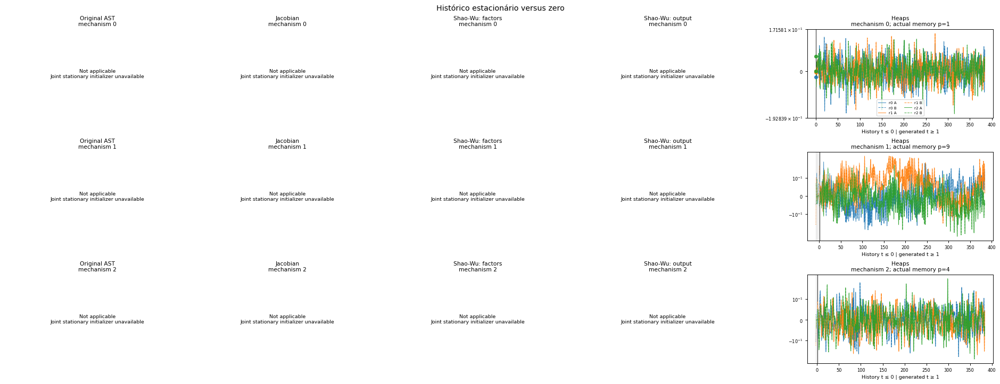

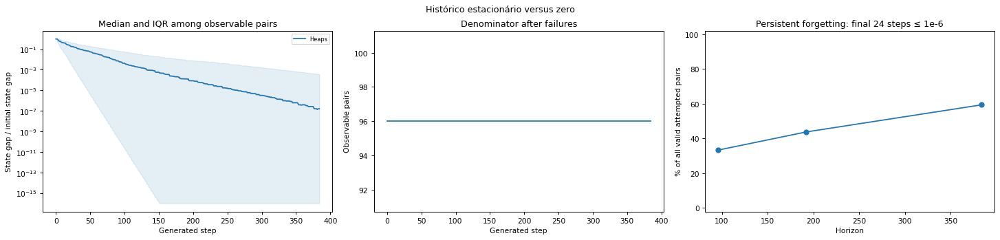

,block,method,case,horizon,mechanisms,pairs,pair_explosions,surviving_pairs,forgotten_pairs,median_final_state_gap,median_settling_step_achieved,weighted_checks,pair_explosion_pct,forgotten_pct_all_pairs,forgotten_pct_survivors
2,Histórico estacionário versus zero,Heaps,Histórico estacionário versus zero,384,32,96,0,96,57,0.0,58.0,0,0.0,59.375,59.375


In [4]:
result = show_pair('Histórico estacionário versus zero', HistorySpec('stationary', 'stationary'), HistorySpec('zero', 'zero'), CONFIG)

**O que foi feito:** A grade mostra os dois caminhos de cada par. O painel seguinte compara a distância normalizada, os pares ainda observáveis e o percentual de esquecimento; falhas ficam ausentes nas distâncias e presentes no denominador das taxas.

## 4. Ciclo completo versus metade

Usamos amplitude 0,5 e variamos memória e período. Embora os históricos possam ter comprimentos distintos, a distância de estado usa exatamente os p lags requeridos, alinhados em t=0.

### Memória até 24; período 96

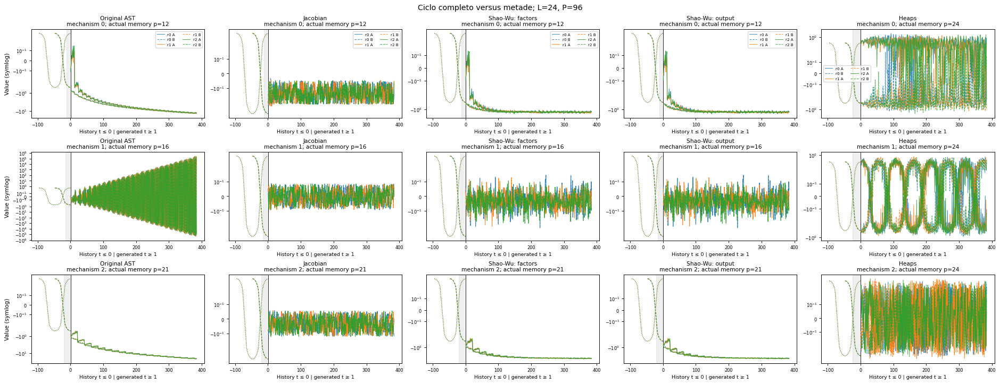

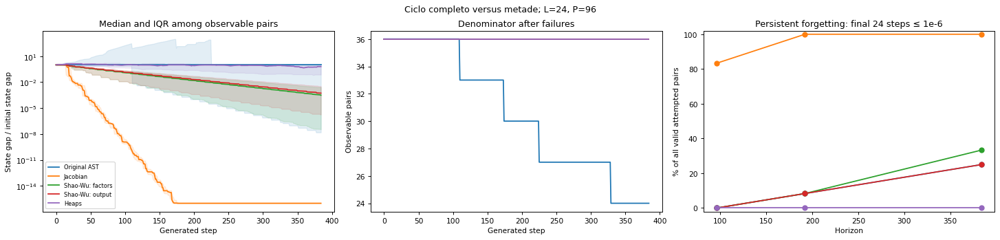

,block,method,case,horizon,mechanisms,pairs,pair_explosions,surviving_pairs,forgotten_pairs,median_final_state_gap,median_settling_step_achieved,weighted_checks,pair_explosion_pct,forgotten_pct_all_pairs,forgotten_pct_survivors
2,"Ciclo completo versus metade; L=24, P=96",Original AST,"Ciclo completo versus metade; L=24, P=96",384,12,36,12,24,9,0.997859,237.0,0,33.333333,25.000000,37.500000
5,"Ciclo completo versus metade; L=24, P=96",Jacobian,"Ciclo completo versus metade; L=24, P=96",384,12,36,0,36,36,0.000000,69.5,36,0.000000,100.000000,100.000000
8,"Ciclo completo versus metade; L=24, P=96",Shao-Wu: factors,"Ciclo completo versus metade; L=24, P=96",384,12,36,0,36,12,0.000310,254.5,0,0.000000,33.333333,33.333333
11,"Ciclo completo versus metade; L=24, P=96",Shao-Wu: output,"Ciclo completo versus metade; L=24, P=96",384,12,36,0,36,9,0.000535,236.0,0,0.000000,25.000000,25.000000
14,"Ciclo completo versus metade; L=24, P=96",Heaps,"Ciclo completo versus metade; L=24, P=96",384,12,36,0,36,0,0.631195,NaN,0,0.000000,0.000000,0.000000


In [5]:
result = show_pair('Ciclo completo versus metade; L=24, P=96', HistorySpec('A', 'cosine', .5, 0.0, 96, 1.0), HistorySpec('B', 'cosine', .5, 0.0, 96, 0.5), cyclic_config(24))

**O que foi feito:** Avaliamos a influência do recorte ou da soma escalar mantendo a equação e a sequência futura de inovações. A faixa entre quartis descreve a dispersão das distâncias entre os pares ainda observáveis.

### Memória até 24; período 192

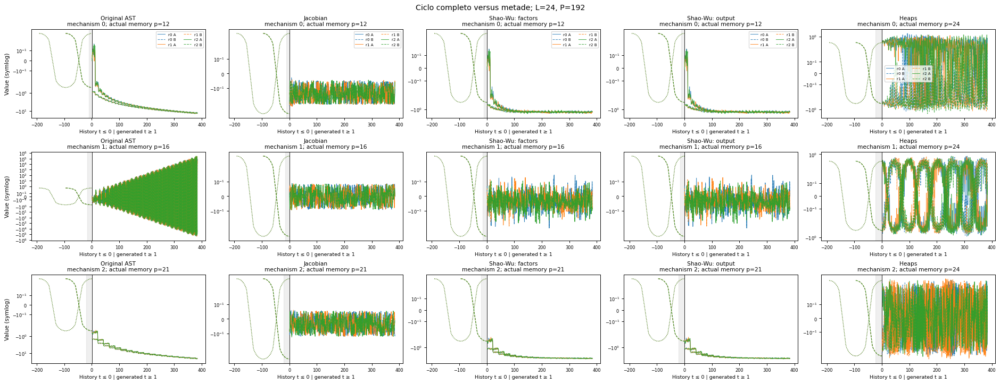

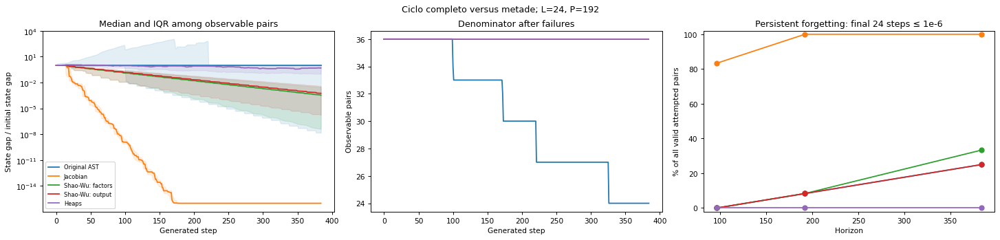

,block,method,case,horizon,mechanisms,pairs,pair_explosions,surviving_pairs,forgotten_pairs,median_final_state_gap,median_settling_step_achieved,weighted_checks,pair_explosion_pct,forgotten_pct_all_pairs,forgotten_pct_survivors
2,"Ciclo completo versus metade; L=24, P=192",Original AST,"Ciclo completo versus metade; L=24, P=192",384,12,36,12,24,9,0.999465,238.0,0,33.333333,25.000000,37.500000
5,"Ciclo completo versus metade; L=24, P=192",Jacobian,"Ciclo completo versus metade; L=24, P=192",384,12,36,0,36,36,0.000000,69.5,36,0.000000,100.000000,100.000000
8,"Ciclo completo versus metade; L=24, P=192",Shao-Wu: factors,"Ciclo completo versus metade; L=24, P=192",384,12,36,0,36,12,0.000338,254.5,0,0.000000,33.333333,33.333333
11,"Ciclo completo versus metade; L=24, P=192",Shao-Wu: output,"Ciclo completo versus metade; L=24, P=192",384,12,36,0,36,9,0.000564,236.0,0,0.000000,25.000000,25.000000
14,"Ciclo completo versus metade; L=24, P=192",Heaps,"Ciclo completo versus metade; L=24, P=192",384,12,36,0,36,0,0.489561,NaN,0,0.000000,0.000000,0.000000


In [6]:
result = show_pair('Ciclo completo versus metade; L=24, P=192', HistorySpec('A', 'cosine', .5, 0.0, 192, 1.0), HistorySpec('B', 'cosine', .5, 0.0, 192, 0.5), cyclic_config(24))

**O que foi feito:** Avaliamos a influência do recorte ou da soma escalar mantendo a equação e a sequência futura de inovações. A faixa entre quartis descreve a dispersão das distâncias entre os pares ainda observáveis.

### Memória até 48; período 192

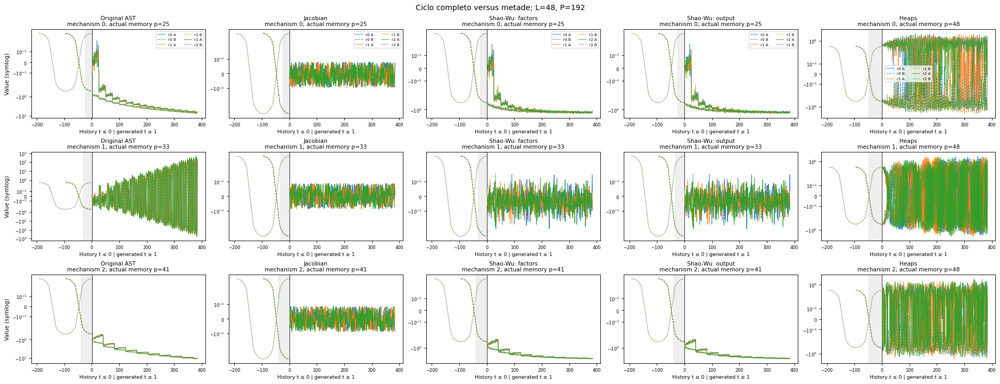

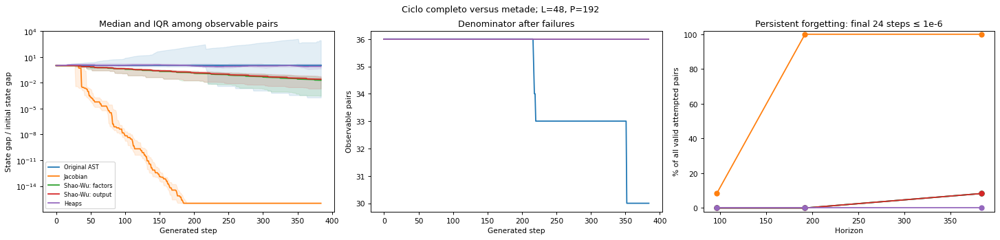

,block,method,case,horizon,mechanisms,pairs,pair_explosions,surviving_pairs,forgotten_pairs,median_final_state_gap,median_settling_step_achieved,weighted_checks,pair_explosion_pct,forgotten_pct_all_pairs,forgotten_pct_survivors
2,"Ciclo completo versus metade; L=48, P=192",Original AST,"Ciclo completo versus metade; L=48, P=192",384,12,36,6,30,3,0.999465,297.0,0,16.666667,8.333333,10.000000
5,"Ciclo completo versus metade; L=48, P=192",Jacobian,"Ciclo completo versus metade; L=48, P=192",384,12,36,0,36,36,0.000000,81.5,36,0.000000,100.000000,100.000000
8,"Ciclo completo versus metade; L=48, P=192",Shao-Wu: factors,"Ciclo completo versus metade; L=48, P=192",384,12,36,0,36,3,0.019838,297.0,0,0.000000,8.333333,8.333333
11,"Ciclo completo versus metade; L=48, P=192",Shao-Wu: output,"Ciclo completo versus metade; L=48, P=192",384,12,36,0,36,3,0.025795,297.0,0,0.000000,8.333333,8.333333
14,"Ciclo completo versus metade; L=48, P=192",Heaps,"Ciclo completo versus metade; L=48, P=192",384,12,36,0,36,0,0.800228,NaN,0,0.000000,0.000000,0.000000


In [7]:
result = show_pair('Ciclo completo versus metade; L=48, P=192', HistorySpec('A', 'cosine', .5, 0.0, 192, 1.0), HistorySpec('B', 'cosine', .5, 0.0, 192, 0.5), cyclic_config(48))

**O que foi feito:** Avaliamos a influência do recorte ou da soma escalar mantendo a equação e a sequência futura de inovações. A faixa entre quartis descreve a dispersão das distâncias entre os pares ainda observáveis.

### Memória até 48; período 384

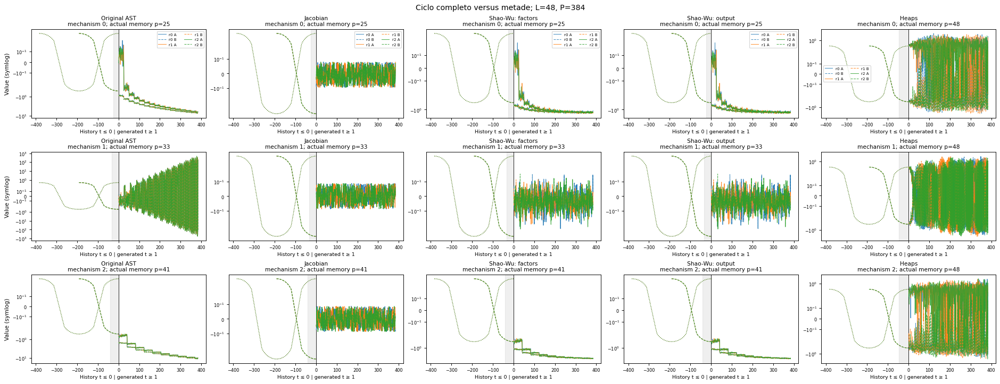

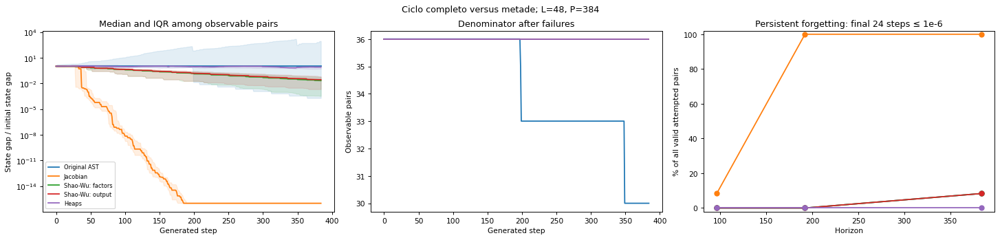

,block,method,case,horizon,mechanisms,pairs,pair_explosions,surviving_pairs,forgotten_pairs,median_final_state_gap,median_settling_step_achieved,weighted_checks,pair_explosion_pct,forgotten_pct_all_pairs,forgotten_pct_survivors
2,"Ciclo completo versus metade; L=48, P=384",Original AST,"Ciclo completo versus metade; L=48, P=384",384,12,36,6,30,3,0.999866,297.0,0,16.666667,8.333333,10.000000
5,"Ciclo completo versus metade; L=48, P=384",Jacobian,"Ciclo completo versus metade; L=48, P=384",384,12,36,0,36,36,0.000000,81.5,36,0.000000,100.000000,100.000000
8,"Ciclo completo versus metade; L=48, P=384",Shao-Wu: factors,"Ciclo completo versus metade; L=48, P=384",384,12,36,0,36,3,0.021095,297.0,0,0.000000,8.333333,8.333333
11,"Ciclo completo versus metade; L=48, P=384",Shao-Wu: output,"Ciclo completo versus metade; L=48, P=384",384,12,36,0,36,3,0.027055,297.0,0,0.000000,8.333333,8.333333
14,"Ciclo completo versus metade; L=48, P=384",Heaps,"Ciclo completo versus metade; L=48, P=384",384,12,36,0,36,0,0.803308,NaN,0,0.000000,0.000000,0.000000


In [8]:
result = show_pair('Ciclo completo versus metade; L=48, P=384', HistorySpec('A', 'cosine', .5, 0.0, 384, 1.0), HistorySpec('B', 'cosine', .5, 0.0, 384, 0.5), cyclic_config(48))

**O que foi feito:** Avaliamos a influência do recorte ou da soma escalar mantendo a equação e a sequência futura de inovações. A faixa entre quartis descreve a dispersão das distâncias entre os pares ainda observáveis.

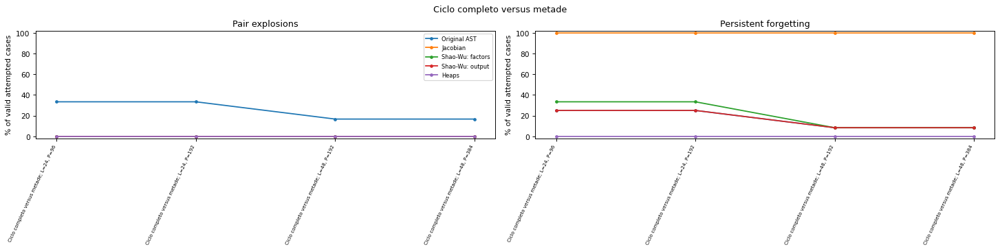

In [9]:
section_summary = pd.concat(SUMMARY_BLOCKS[-4:], ignore_index=True)
plot_condition_summary(section_summary, 'Ciclo completo versus metade', forgetting=True)
plt.show()

**O que foi feito:** Comparamos os quatro pares de memória e período usando a taxa de explosões e a taxa de esquecimento entre todos os pares executados.

## 5. Ciclo completo versus quarto

Usamos amplitude 0,5 e variamos memória e período. Embora os históricos possam ter comprimentos distintos, a distância de estado usa exatamente os p lags requeridos, alinhados em t=0.

### Memória até 24; período 96

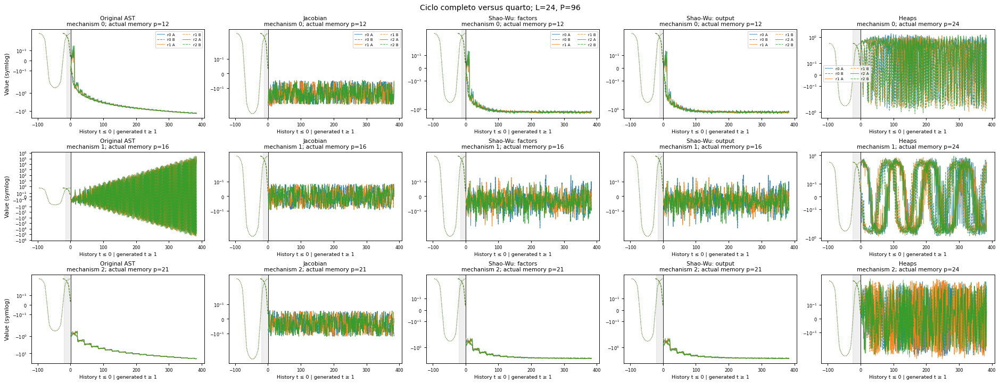

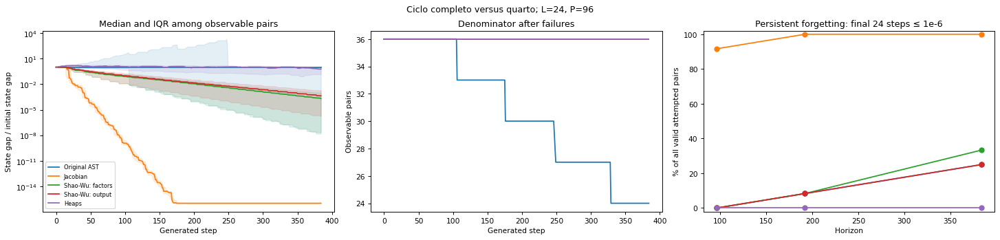

,block,method,case,horizon,mechanisms,pairs,pair_explosions,surviving_pairs,forgotten_pairs,median_final_state_gap,median_settling_step_achieved,weighted_checks,pair_explosion_pct,forgotten_pct_all_pairs,forgotten_pct_survivors
2,"Ciclo completo versus quarto; L=24, P=96",Original AST,"Ciclo completo versus quarto; L=24, P=96",384,12,36,12,24,9,0.466228,216.0,0,33.333333,25.000000,37.500000
5,"Ciclo completo versus quarto; L=24, P=96",Jacobian,"Ciclo completo versus quarto; L=24, P=96",384,12,36,0,36,36,0.000000,67.5,36,0.000000,100.000000,100.000000
8,"Ciclo completo versus quarto; L=24, P=96",Shao-Wu: factors,"Ciclo completo versus quarto; L=24, P=96",384,12,36,0,36,12,0.000094,237.5,0,0.000000,33.333333,33.333333
11,"Ciclo completo versus quarto; L=24, P=96",Shao-Wu: output,"Ciclo completo versus quarto; L=24, P=96",384,12,36,0,36,9,0.000199,215.0,0,0.000000,25.000000,25.000000
14,"Ciclo completo versus quarto; L=24, P=96",Heaps,"Ciclo completo versus quarto; L=24, P=96",384,12,36,0,36,0,0.305951,NaN,0,0.000000,0.000000,0.000000


In [10]:
result = show_pair('Ciclo completo versus quarto; L=24, P=96', HistorySpec('A', 'cosine', .5, 0.0, 96, 1.0), HistorySpec('B', 'cosine', .5, 0.0, 96, 0.25), cyclic_config(24))

**O que foi feito:** Avaliamos a influência do recorte ou da soma escalar mantendo a equação e a sequência futura de inovações. A faixa entre quartis descreve a dispersão das distâncias entre os pares ainda observáveis.

### Memória até 24; período 192

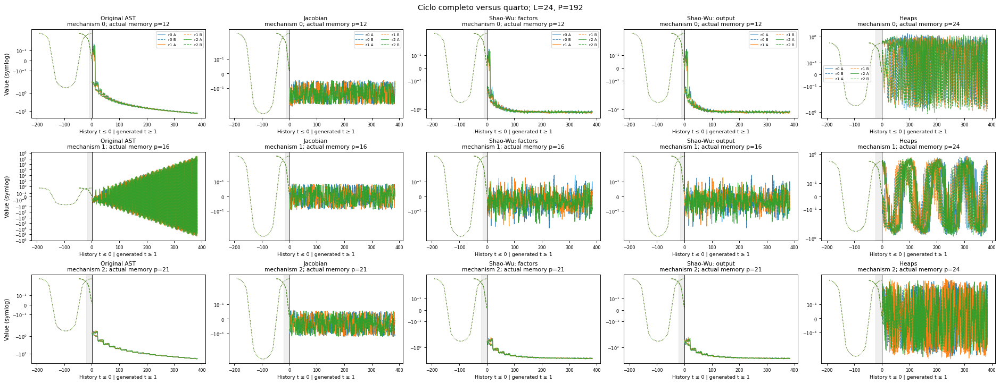

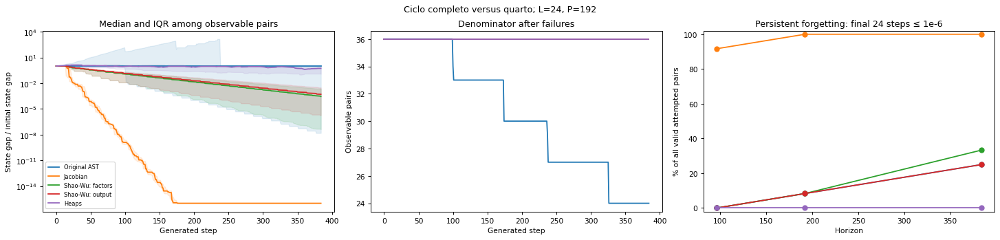

,block,method,case,horizon,mechanisms,pairs,pair_explosions,surviving_pairs,forgotten_pairs,median_final_state_gap,median_settling_step_achieved,weighted_checks,pair_explosion_pct,forgotten_pct_all_pairs,forgotten_pct_survivors
2,"Ciclo completo versus quarto; L=24, P=192",Original AST,"Ciclo completo versus quarto; L=24, P=192",384,12,36,12,24,9,0.483373,217.0,0,33.333333,25.000000,37.500000
5,"Ciclo completo versus quarto; L=24, P=192",Jacobian,"Ciclo completo versus quarto; L=24, P=192",384,12,36,0,36,36,0.000000,69.5,36,0.000000,100.000000,100.000000
8,"Ciclo completo versus quarto; L=24, P=192",Shao-Wu: factors,"Ciclo completo versus quarto; L=24, P=192",384,12,36,0,36,12,0.000137,238.0,0,0.000000,33.333333,33.333333
11,"Ciclo completo versus quarto; L=24, P=192",Shao-Wu: output,"Ciclo completo versus quarto; L=24, P=192",384,12,36,0,36,9,0.000246,216.0,0,0.000000,25.000000,25.000000
14,"Ciclo completo versus quarto; L=24, P=192",Heaps,"Ciclo completo versus quarto; L=24, P=192",384,12,36,0,36,0,0.257230,NaN,0,0.000000,0.000000,0.000000


In [11]:
result = show_pair('Ciclo completo versus quarto; L=24, P=192', HistorySpec('A', 'cosine', .5, 0.0, 192, 1.0), HistorySpec('B', 'cosine', .5, 0.0, 192, 0.25), cyclic_config(24))

**O que foi feito:** Avaliamos a influência do recorte ou da soma escalar mantendo a equação e a sequência futura de inovações. A faixa entre quartis descreve a dispersão das distâncias entre os pares ainda observáveis.

### Memória até 48; período 192

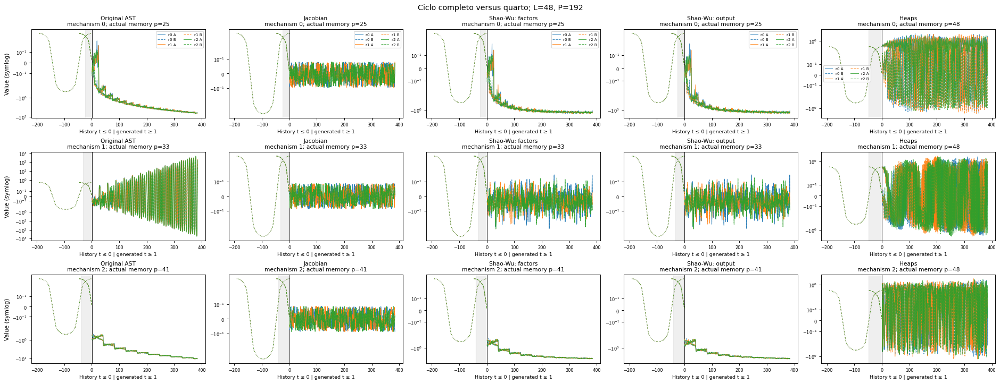

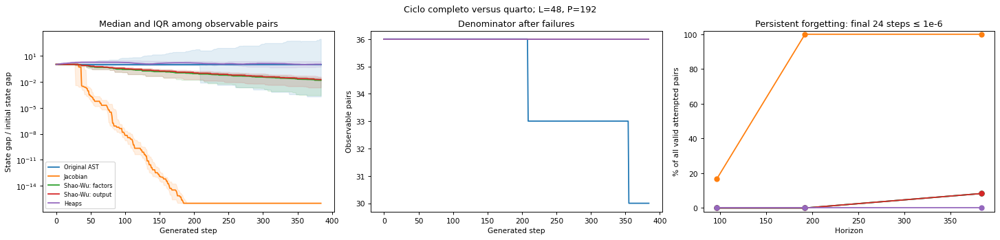

,block,method,case,horizon,mechanisms,pairs,pair_explosions,surviving_pairs,forgotten_pairs,median_final_state_gap,median_settling_step_achieved,weighted_checks,pair_explosion_pct,forgotten_pct_all_pairs,forgotten_pct_survivors
2,"Ciclo completo versus quarto; L=48, P=192",Original AST,"Ciclo completo versus quarto; L=48, P=192",384,12,36,6,30,3,0.483373,297.0,0,16.666667,8.333333,10.000000
5,"Ciclo completo versus quarto; L=48, P=192",Jacobian,"Ciclo completo versus quarto; L=48, P=192",384,12,36,0,36,36,0.000000,79.5,36,0.000000,100.000000,100.000000
8,"Ciclo completo versus quarto; L=48, P=192",Shao-Wu: factors,"Ciclo completo versus quarto; L=48, P=192",384,12,36,0,36,3,0.007054,270.0,0,0.000000,8.333333,8.333333
11,"Ciclo completo versus quarto; L=48, P=192",Shao-Wu: output,"Ciclo completo versus quarto; L=48, P=192",384,12,36,0,36,3,0.008744,270.0,0,0.000000,8.333333,8.333333
14,"Ciclo completo versus quarto; L=48, P=192",Heaps,"Ciclo completo versus quarto; L=48, P=192",384,12,36,0,36,0,0.508687,NaN,0,0.000000,0.000000,0.000000


In [12]:
result = show_pair('Ciclo completo versus quarto; L=48, P=192', HistorySpec('A', 'cosine', .5, 0.0, 192, 1.0), HistorySpec('B', 'cosine', .5, 0.0, 192, 0.25), cyclic_config(48))

**O que foi feito:** Avaliamos a influência do recorte ou da soma escalar mantendo a equação e a sequência futura de inovações. A faixa entre quartis descreve a dispersão das distâncias entre os pares ainda observáveis.

### Memória até 48; período 384

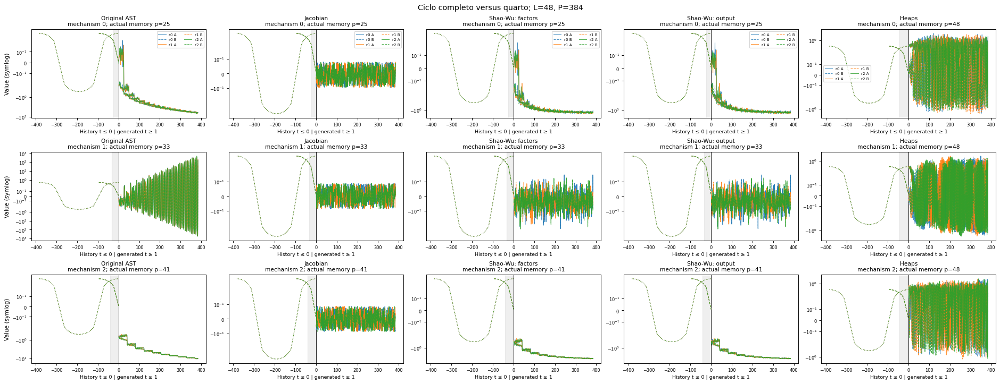

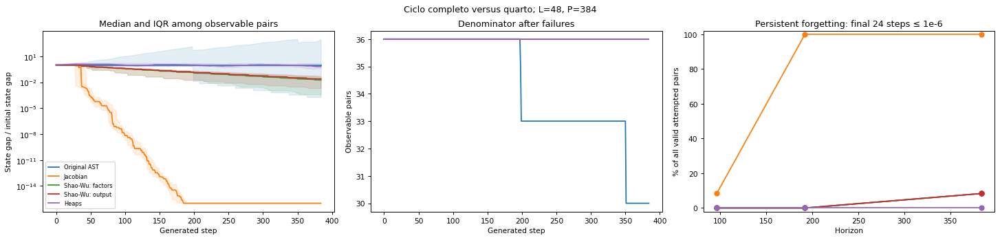

,block,method,case,horizon,mechanisms,pairs,pair_explosions,surviving_pairs,forgotten_pairs,median_final_state_gap,median_settling_step_achieved,weighted_checks,pair_explosion_pct,forgotten_pct_all_pairs,forgotten_pct_survivors
2,"Ciclo completo versus quarto; L=48, P=384",Original AST,"Ciclo completo versus quarto; L=48, P=384",384,12,36,6,30,3,0.491752,297.0,0,16.666667,8.333333,10.000000
5,"Ciclo completo versus quarto; L=48, P=384",Jacobian,"Ciclo completo versus quarto; L=48, P=384",384,12,36,0,36,36,0.000000,81.5,36,0.000000,100.000000,100.000000
8,"Ciclo completo versus quarto; L=48, P=384",Shao-Wu: factors,"Ciclo completo versus quarto; L=48, P=384",384,12,36,0,36,3,0.009041,270.0,0,0.000000,8.333333,8.333333
11,"Ciclo completo versus quarto; L=48, P=384",Shao-Wu: output,"Ciclo completo versus quarto; L=48, P=384",384,12,36,0,36,3,0.011972,270.0,0,0.000000,8.333333,8.333333
14,"Ciclo completo versus quarto; L=48, P=384",Heaps,"Ciclo completo versus quarto; L=48, P=384",384,12,36,0,36,0,0.339389,NaN,0,0.000000,0.000000,0.000000


In [13]:
result = show_pair('Ciclo completo versus quarto; L=48, P=384', HistorySpec('A', 'cosine', .5, 0.0, 384, 1.0), HistorySpec('B', 'cosine', .5, 0.0, 384, 0.25), cyclic_config(48))

**O que foi feito:** Avaliamos a influência do recorte ou da soma escalar mantendo a equação e a sequência futura de inovações. A faixa entre quartis descreve a dispersão das distâncias entre os pares ainda observáveis.

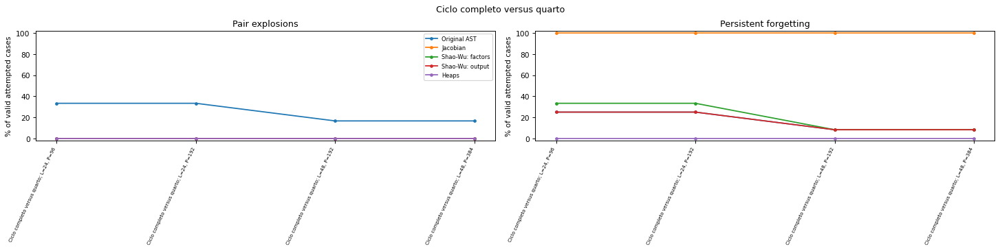

In [14]:
section_summary = pd.concat(SUMMARY_BLOCKS[-4:], ignore_index=True)
plot_condition_summary(section_summary, 'Ciclo completo versus quarto', forgetting=True)
plt.show()

**O que foi feito:** Comparamos os quatro pares de memória e período usando a taxa de explosões e a taxa de esquecimento entre todos os pares executados.

## 6. Ciclo completo versus ciclo completo + 0,5

Usamos amplitude 0,5 e variamos memória e período. Embora os históricos possam ter comprimentos distintos, a distância de estado usa exatamente os p lags requeridos, alinhados em t=0.

### Memória até 24; período 96

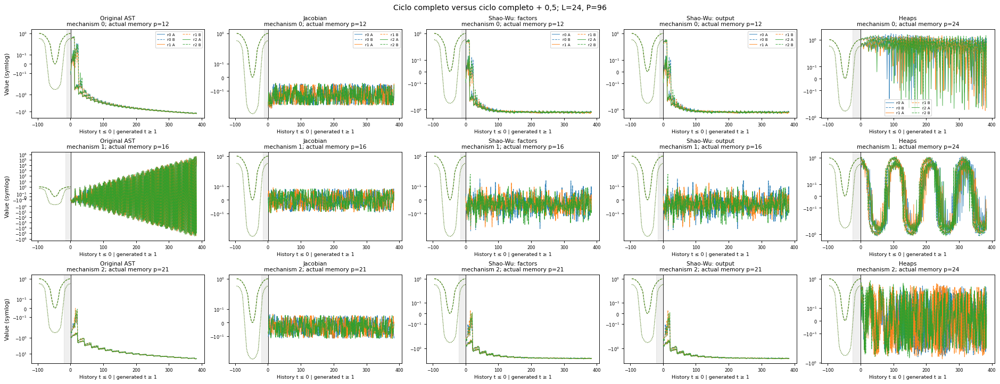

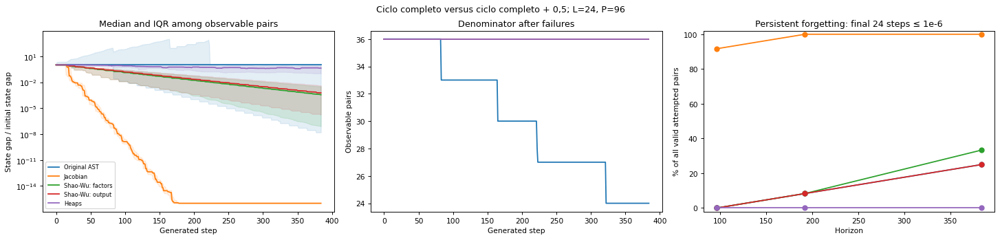

,block,method,case,horizon,mechanisms,pairs,pair_explosions,surviving_pairs,forgotten_pairs,median_final_state_gap,median_settling_step_achieved,weighted_checks,pair_explosion_pct,forgotten_pct_all_pairs,forgotten_pct_survivors
2,"Ciclo completo versus ciclo completo + 0,5; L=...",Original AST,"Ciclo completo versus ciclo completo + 0,5; L=...",384,12,36,12,24,9,0.500000,235.0,0,33.333333,25.000000,37.500000
5,"Ciclo completo versus ciclo completo + 0,5; L=...",Jacobian,"Ciclo completo versus ciclo completo + 0,5; L=...",384,12,36,0,36,36,0.000000,69.5,36,0.000000,100.000000,100.000000
8,"Ciclo completo versus ciclo completo + 0,5; L=...",Shao-Wu: factors,"Ciclo completo versus ciclo completo + 0,5; L=...",384,12,36,0,36,12,0.000174,238.5,0,0.000000,33.333333,33.333333
11,"Ciclo completo versus ciclo completo + 0,5; L=...",Shao-Wu: output,"Ciclo completo versus ciclo completo + 0,5; L=...",384,12,36,0,36,9,0.000287,217.0,0,0.000000,25.000000,25.000000
14,"Ciclo completo versus ciclo completo + 0,5; L=...",Heaps,"Ciclo completo versus ciclo completo + 0,5; L=...",384,12,36,0,36,0,0.213218,NaN,0,0.000000,0.000000,0.000000


In [15]:
result = show_pair('Ciclo completo versus ciclo completo + 0,5; L=24, P=96', HistorySpec('A', 'cosine', .5, 0.0, 96, 1.0), HistorySpec('B', 'cosine', .5, 0.5, 96, 1.0), cyclic_config(24))

**O que foi feito:** Avaliamos a influência do recorte ou da soma escalar mantendo a equação e a sequência futura de inovações. A faixa entre quartis descreve a dispersão das distâncias entre os pares ainda observáveis.

### Memória até 24; período 192

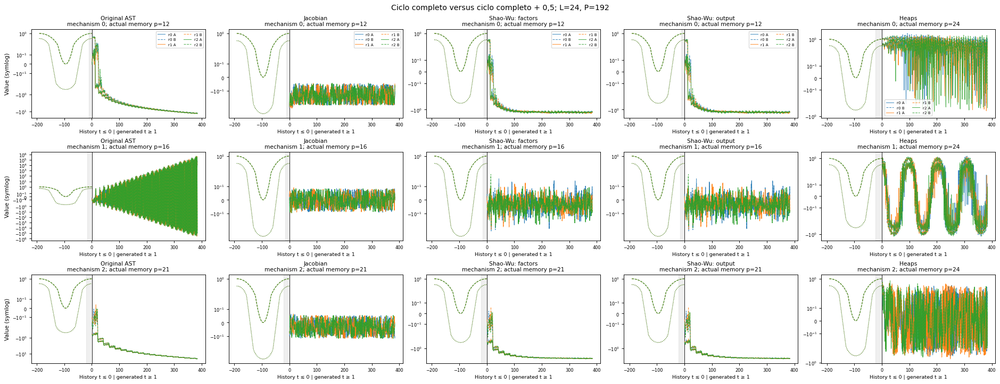

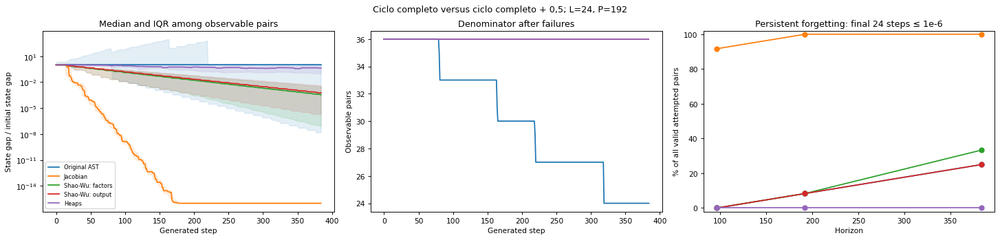

,block,method,case,horizon,mechanisms,pairs,pair_explosions,surviving_pairs,forgotten_pairs,median_final_state_gap,median_settling_step_achieved,weighted_checks,pair_explosion_pct,forgotten_pct_all_pairs,forgotten_pct_survivors
2,"Ciclo completo versus ciclo completo + 0,5; L=...",Original AST,"Ciclo completo versus ciclo completo + 0,5; L=...",384,12,36,12,24,9,0.500000,235.0,0,33.333333,25.000000,37.500000
5,"Ciclo completo versus ciclo completo + 0,5; L=...",Jacobian,"Ciclo completo versus ciclo completo + 0,5; L=...",384,12,36,0,36,36,0.000000,69.5,36,0.000000,100.000000,100.000000
8,"Ciclo completo versus ciclo completo + 0,5; L=...",Shao-Wu: factors,"Ciclo completo versus ciclo completo + 0,5; L=...",384,12,36,0,36,12,0.000174,238.5,0,0.000000,33.333333,33.333333
11,"Ciclo completo versus ciclo completo + 0,5; L=...",Shao-Wu: output,"Ciclo completo versus ciclo completo + 0,5; L=...",384,12,36,0,36,9,0.000287,217.0,0,0.000000,25.000000,25.000000
14,"Ciclo completo versus ciclo completo + 0,5; L=...",Heaps,"Ciclo completo versus ciclo completo + 0,5; L=...",384,12,36,0,36,0,0.213218,NaN,0,0.000000,0.000000,0.000000


In [16]:
result = show_pair('Ciclo completo versus ciclo completo + 0,5; L=24, P=192', HistorySpec('A', 'cosine', .5, 0.0, 192, 1.0), HistorySpec('B', 'cosine', .5, 0.5, 192, 1.0), cyclic_config(24))

**O que foi feito:** Avaliamos a influência do recorte ou da soma escalar mantendo a equação e a sequência futura de inovações. A faixa entre quartis descreve a dispersão das distâncias entre os pares ainda observáveis.

### Memória até 48; período 192

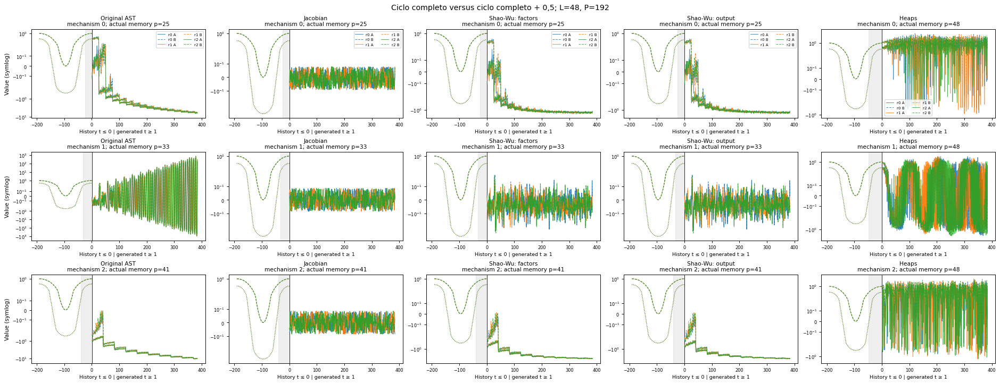

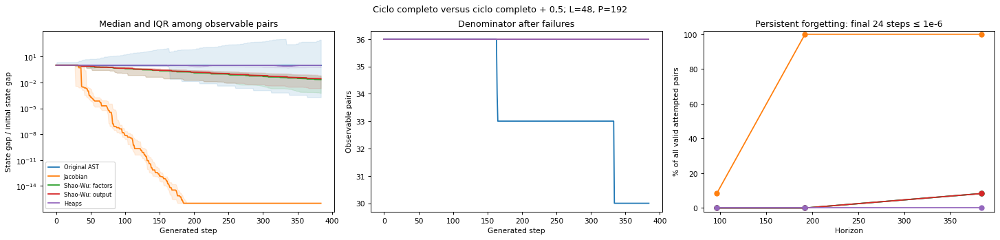

,block,method,case,horizon,mechanisms,pairs,pair_explosions,surviving_pairs,forgotten_pairs,median_final_state_gap,median_settling_step_achieved,weighted_checks,pair_explosion_pct,forgotten_pct_all_pairs,forgotten_pct_survivors
2,"Ciclo completo versus ciclo completo + 0,5; L=...",Original AST,"Ciclo completo versus ciclo completo + 0,5; L=...",384,12,36,6,30,3,0.500000,297.0,0,16.666667,8.333333,10.000000
5,"Ciclo completo versus ciclo completo + 0,5; L=...",Jacobian,"Ciclo completo versus ciclo completo + 0,5; L=...",384,12,36,0,36,36,0.000000,81.5,36,0.000000,100.000000,100.000000
8,"Ciclo completo versus ciclo completo + 0,5; L=...",Shao-Wu: factors,"Ciclo completo versus ciclo completo + 0,5; L=...",384,12,36,0,36,3,0.010767,270.0,0,0.000000,8.333333,8.333333
11,"Ciclo completo versus ciclo completo + 0,5; L=...",Shao-Wu: output,"Ciclo completo versus ciclo completo + 0,5; L=...",384,12,36,0,36,3,0.013747,270.0,0,0.000000,8.333333,8.333333
14,"Ciclo completo versus ciclo completo + 0,5; L=...",Heaps,"Ciclo completo versus ciclo completo + 0,5; L=...",384,12,36,0,36,0,0.481287,NaN,0,0.000000,0.000000,0.000000


In [17]:
result = show_pair('Ciclo completo versus ciclo completo + 0,5; L=48, P=192', HistorySpec('A', 'cosine', .5, 0.0, 192, 1.0), HistorySpec('B', 'cosine', .5, 0.5, 192, 1.0), cyclic_config(48))

**O que foi feito:** Avaliamos a influência do recorte ou da soma escalar mantendo a equação e a sequência futura de inovações. A faixa entre quartis descreve a dispersão das distâncias entre os pares ainda observáveis.

### Memória até 48; período 384

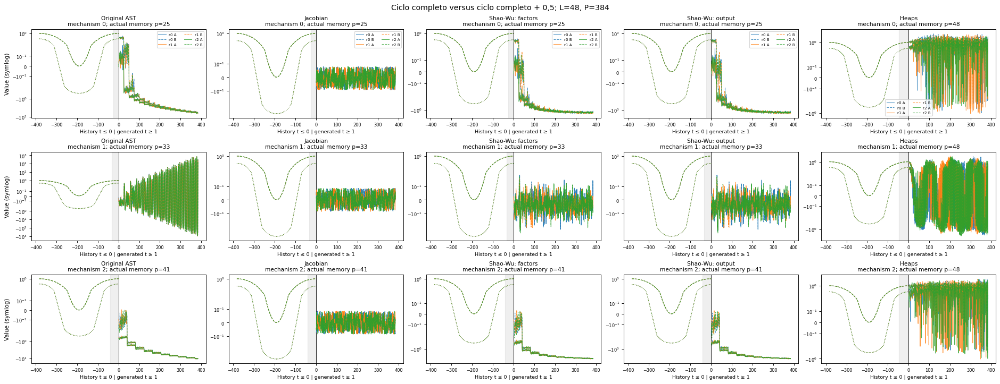

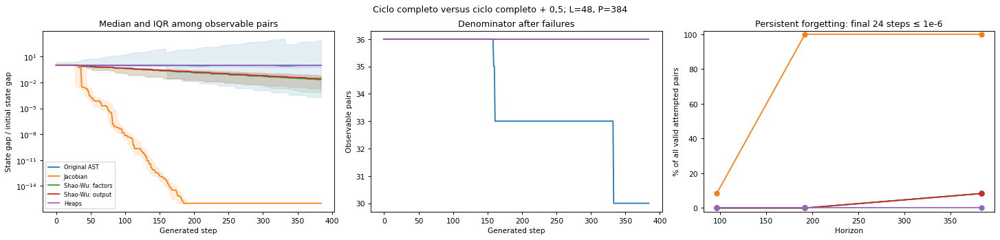

,block,method,case,horizon,mechanisms,pairs,pair_explosions,surviving_pairs,forgotten_pairs,median_final_state_gap,median_settling_step_achieved,weighted_checks,pair_explosion_pct,forgotten_pct_all_pairs,forgotten_pct_survivors
2,"Ciclo completo versus ciclo completo + 0,5; L=...",Original AST,"Ciclo completo versus ciclo completo + 0,5; L=...",384,12,36,6,30,3,0.500000,297.0,0,16.666667,8.333333,10.000000
5,"Ciclo completo versus ciclo completo + 0,5; L=...",Jacobian,"Ciclo completo versus ciclo completo + 0,5; L=...",384,12,36,0,36,36,0.000000,81.5,36,0.000000,100.000000,100.000000
8,"Ciclo completo versus ciclo completo + 0,5; L=...",Shao-Wu: factors,"Ciclo completo versus ciclo completo + 0,5; L=...",384,12,36,0,36,3,0.010767,270.0,0,0.000000,8.333333,8.333333
11,"Ciclo completo versus ciclo completo + 0,5; L=...",Shao-Wu: output,"Ciclo completo versus ciclo completo + 0,5; L=...",384,12,36,0,36,3,0.013747,270.0,0,0.000000,8.333333,8.333333
14,"Ciclo completo versus ciclo completo + 0,5; L=...",Heaps,"Ciclo completo versus ciclo completo + 0,5; L=...",384,12,36,0,36,0,0.481287,NaN,0,0.000000,0.000000,0.000000


In [18]:
result = show_pair('Ciclo completo versus ciclo completo + 0,5; L=48, P=384', HistorySpec('A', 'cosine', .5, 0.0, 384, 1.0), HistorySpec('B', 'cosine', .5, 0.5, 384, 1.0), cyclic_config(48))

**O que foi feito:** Avaliamos a influência do recorte ou da soma escalar mantendo a equação e a sequência futura de inovações. A faixa entre quartis descreve a dispersão das distâncias entre os pares ainda observáveis.

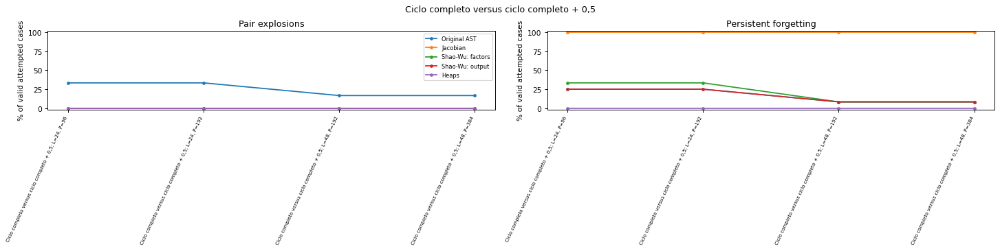

In [19]:
section_summary = pd.concat(SUMMARY_BLOCKS[-4:], ignore_index=True)
plot_condition_summary(section_summary, 'Ciclo completo versus ciclo completo + 0,5', forgetting=True)
plt.show()

**O que foi feito:** Comparamos os quatro pares de memória e período usando a taxa de explosões e a taxa de esquecimento entre todos os pares executados.

## 7. Meio ciclo versus meio ciclo + 0,5

Usamos amplitude 0,5 e variamos memória e período. Embora os históricos possam ter comprimentos distintos, a distância de estado usa exatamente os p lags requeridos, alinhados em t=0.

### Memória até 24; período 96

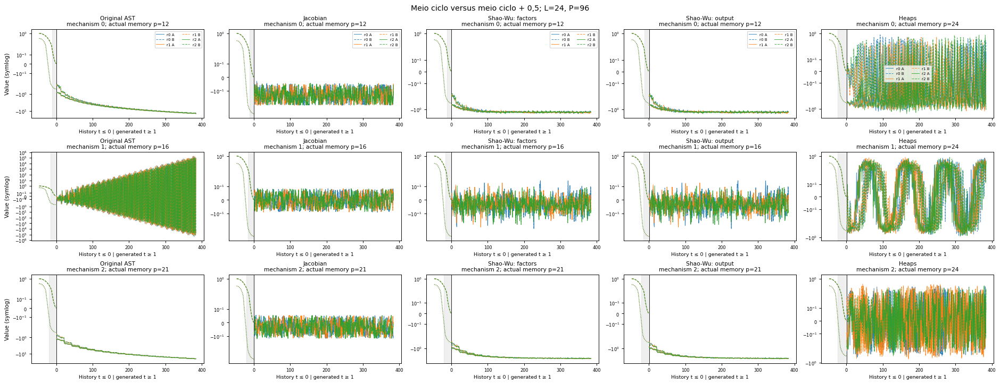

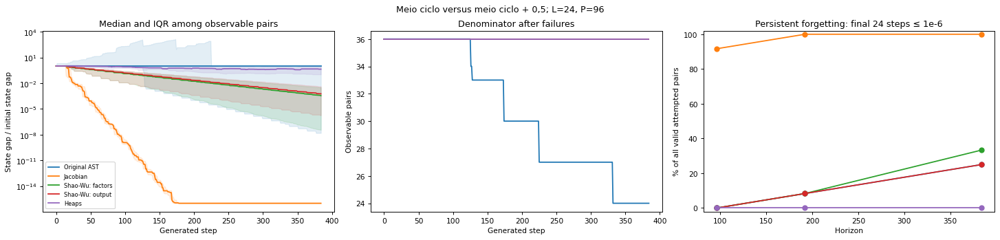

,block,method,case,horizon,mechanisms,pairs,pair_explosions,surviving_pairs,forgotten_pairs,median_final_state_gap,median_settling_step_achieved,weighted_checks,pair_explosion_pct,forgotten_pct_all_pairs,forgotten_pct_survivors
2,"Meio ciclo versus meio ciclo + 0,5; L=24, P=96",Original AST,"Meio ciclo versus meio ciclo + 0,5; L=24, P=96",384,12,36,12,24,9,0.500000,235.0,0,33.333333,25.000000,37.500000
5,"Meio ciclo versus meio ciclo + 0,5; L=24, P=96",Jacobian,"Meio ciclo versus meio ciclo + 0,5; L=24, P=96",384,12,36,0,36,36,0.000000,69.5,36,0.000000,100.000000,100.000000
8,"Meio ciclo versus meio ciclo + 0,5; L=24, P=96",Shao-Wu: factors,"Meio ciclo versus meio ciclo + 0,5; L=24, P=96",384,12,36,0,36,12,0.000174,238.5,0,0.000000,33.333333,33.333333
11,"Meio ciclo versus meio ciclo + 0,5; L=24, P=96",Shao-Wu: output,"Meio ciclo versus meio ciclo + 0,5; L=24, P=96",384,12,36,0,36,9,0.000287,217.0,0,0.000000,25.000000,25.000000
14,"Meio ciclo versus meio ciclo + 0,5; L=24, P=96",Heaps,"Meio ciclo versus meio ciclo + 0,5; L=24, P=96",384,12,36,0,36,0,0.213218,NaN,0,0.000000,0.000000,0.000000


In [20]:
result = show_pair('Meio ciclo versus meio ciclo + 0,5; L=24, P=96', HistorySpec('A', 'cosine', .5, 0.0, 96, 0.5), HistorySpec('B', 'cosine', .5, 0.5, 96, 0.5), cyclic_config(24))

**O que foi feito:** Avaliamos a influência do recorte ou da soma escalar mantendo a equação e a sequência futura de inovações. A faixa entre quartis descreve a dispersão das distâncias entre os pares ainda observáveis.

### Memória até 24; período 192

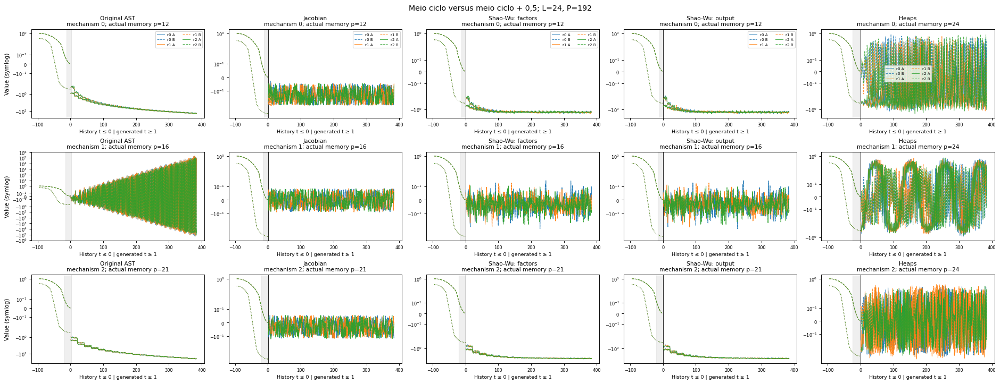

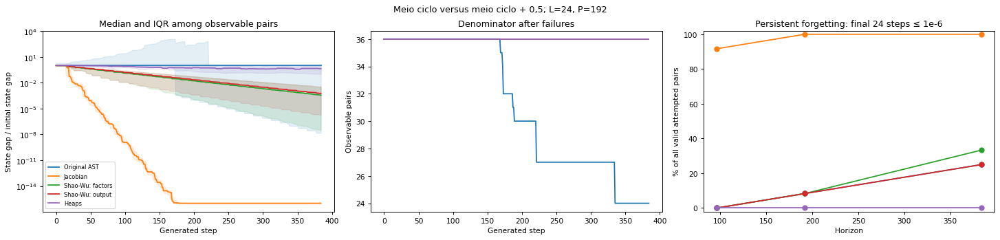

,block,method,case,horizon,mechanisms,pairs,pair_explosions,surviving_pairs,forgotten_pairs,median_final_state_gap,median_settling_step_achieved,weighted_checks,pair_explosion_pct,forgotten_pct_all_pairs,forgotten_pct_survivors
2,"Meio ciclo versus meio ciclo + 0,5; L=24, P=192",Original AST,"Meio ciclo versus meio ciclo + 0,5; L=24, P=192",384,12,36,12,24,9,0.500000,235.0,0,33.333333,25.000000,37.500000
5,"Meio ciclo versus meio ciclo + 0,5; L=24, P=192",Jacobian,"Meio ciclo versus meio ciclo + 0,5; L=24, P=192",384,12,36,0,36,36,0.000000,69.5,36,0.000000,100.000000,100.000000
8,"Meio ciclo versus meio ciclo + 0,5; L=24, P=192",Shao-Wu: factors,"Meio ciclo versus meio ciclo + 0,5; L=24, P=192",384,12,36,0,36,12,0.000174,238.5,0,0.000000,33.333333,33.333333
11,"Meio ciclo versus meio ciclo + 0,5; L=24, P=192",Shao-Wu: output,"Meio ciclo versus meio ciclo + 0,5; L=24, P=192",384,12,36,0,36,9,0.000287,217.0,0,0.000000,25.000000,25.000000
14,"Meio ciclo versus meio ciclo + 0,5; L=24, P=192",Heaps,"Meio ciclo versus meio ciclo + 0,5; L=24, P=192",384,12,36,0,36,0,0.213218,NaN,0,0.000000,0.000000,0.000000


In [21]:
result = show_pair('Meio ciclo versus meio ciclo + 0,5; L=24, P=192', HistorySpec('A', 'cosine', .5, 0.0, 192, 0.5), HistorySpec('B', 'cosine', .5, 0.5, 192, 0.5), cyclic_config(24))

**O que foi feito:** Avaliamos a influência do recorte ou da soma escalar mantendo a equação e a sequência futura de inovações. A faixa entre quartis descreve a dispersão das distâncias entre os pares ainda observáveis.

### Memória até 48; período 192

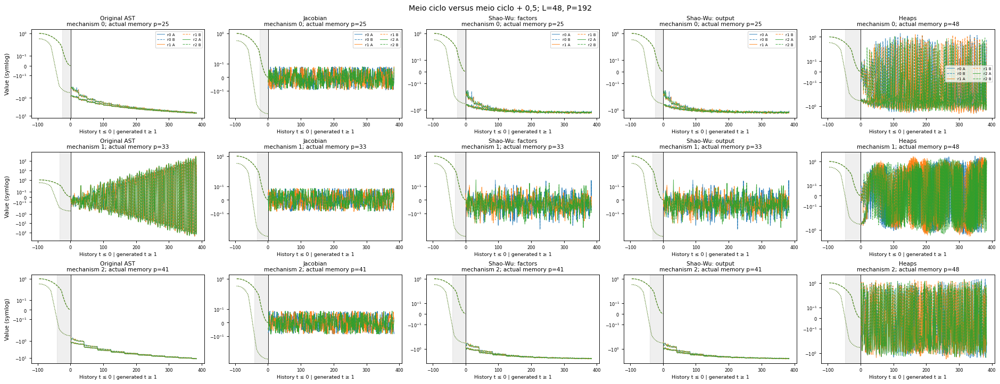

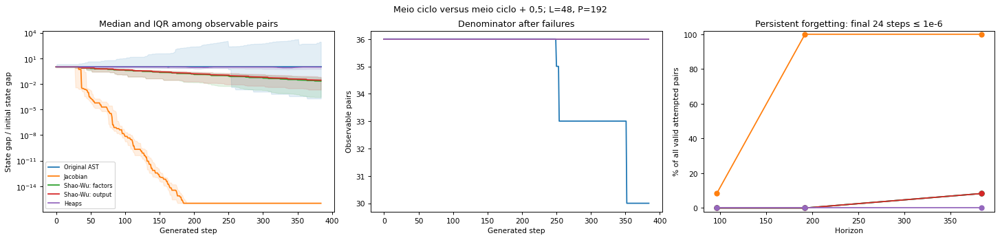

,block,method,case,horizon,mechanisms,pairs,pair_explosions,surviving_pairs,forgotten_pairs,median_final_state_gap,median_settling_step_achieved,weighted_checks,pair_explosion_pct,forgotten_pct_all_pairs,forgotten_pct_survivors
2,"Meio ciclo versus meio ciclo + 0,5; L=48, P=192",Original AST,"Meio ciclo versus meio ciclo + 0,5; L=48, P=192",384,12,36,6,30,3,0.500000,297.0,0,16.666667,8.333333,10.000000
5,"Meio ciclo versus meio ciclo + 0,5; L=48, P=192",Jacobian,"Meio ciclo versus meio ciclo + 0,5; L=48, P=192",384,12,36,0,36,36,0.000000,81.5,36,0.000000,100.000000,100.000000
8,"Meio ciclo versus meio ciclo + 0,5; L=48, P=192",Shao-Wu: factors,"Meio ciclo versus meio ciclo + 0,5; L=48, P=192",384,12,36,0,36,3,0.010767,270.0,0,0.000000,8.333333,8.333333
11,"Meio ciclo versus meio ciclo + 0,5; L=48, P=192",Shao-Wu: output,"Meio ciclo versus meio ciclo + 0,5; L=48, P=192",384,12,36,0,36,3,0.013747,270.0,0,0.000000,8.333333,8.333333
14,"Meio ciclo versus meio ciclo + 0,5; L=48, P=192",Heaps,"Meio ciclo versus meio ciclo + 0,5; L=48, P=192",384,12,36,0,36,0,0.481287,NaN,0,0.000000,0.000000,0.000000


In [22]:
result = show_pair('Meio ciclo versus meio ciclo + 0,5; L=48, P=192', HistorySpec('A', 'cosine', .5, 0.0, 192, 0.5), HistorySpec('B', 'cosine', .5, 0.5, 192, 0.5), cyclic_config(48))

**O que foi feito:** Avaliamos a influência do recorte ou da soma escalar mantendo a equação e a sequência futura de inovações. A faixa entre quartis descreve a dispersão das distâncias entre os pares ainda observáveis.

### Memória até 48; período 384

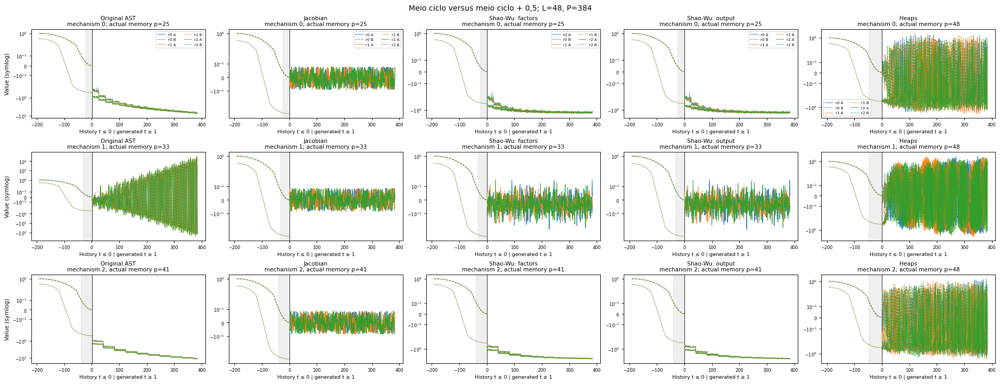

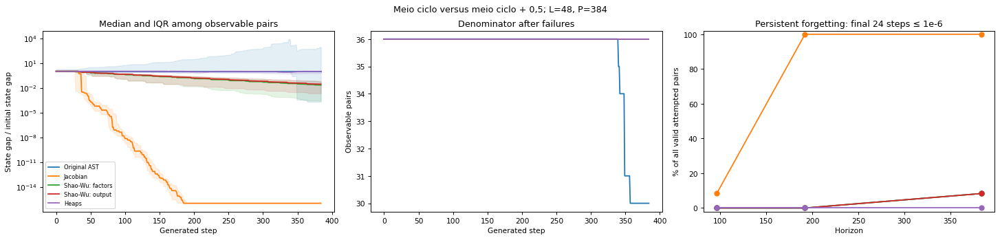

,block,method,case,horizon,mechanisms,pairs,pair_explosions,surviving_pairs,forgotten_pairs,median_final_state_gap,median_settling_step_achieved,weighted_checks,pair_explosion_pct,forgotten_pct_all_pairs,forgotten_pct_survivors
2,"Meio ciclo versus meio ciclo + 0,5; L=48, P=384",Original AST,"Meio ciclo versus meio ciclo + 0,5; L=48, P=384",384,12,36,6,30,3,0.500000,297.0,0,16.666667,8.333333,10.000000
5,"Meio ciclo versus meio ciclo + 0,5; L=48, P=384",Jacobian,"Meio ciclo versus meio ciclo + 0,5; L=48, P=384",384,12,36,0,36,36,0.000000,81.5,36,0.000000,100.000000,100.000000
8,"Meio ciclo versus meio ciclo + 0,5; L=48, P=384",Shao-Wu: factors,"Meio ciclo versus meio ciclo + 0,5; L=48, P=384",384,12,36,0,36,3,0.010767,270.0,0,0.000000,8.333333,8.333333
11,"Meio ciclo versus meio ciclo + 0,5; L=48, P=384",Shao-Wu: output,"Meio ciclo versus meio ciclo + 0,5; L=48, P=384",384,12,36,0,36,3,0.013747,270.0,0,0.000000,8.333333,8.333333
14,"Meio ciclo versus meio ciclo + 0,5; L=48, P=384",Heaps,"Meio ciclo versus meio ciclo + 0,5; L=48, P=384",384,12,36,0,36,0,0.481287,NaN,0,0.000000,0.000000,0.000000


In [23]:
result = show_pair('Meio ciclo versus meio ciclo + 0,5; L=48, P=384', HistorySpec('A', 'cosine', .5, 0.0, 384, 0.5), HistorySpec('B', 'cosine', .5, 0.5, 384, 0.5), cyclic_config(48))

**O que foi feito:** Avaliamos a influência do recorte ou da soma escalar mantendo a equação e a sequência futura de inovações. A faixa entre quartis descreve a dispersão das distâncias entre os pares ainda observáveis.

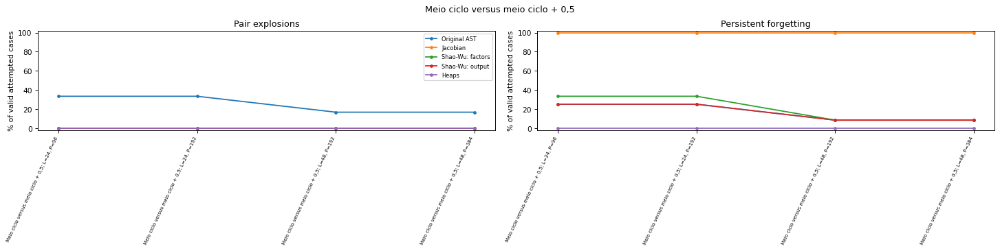

In [24]:
section_summary = pd.concat(SUMMARY_BLOCKS[-4:], ignore_index=True)
plot_condition_summary(section_summary, 'Meio ciclo versus meio ciclo + 0,5', forgetting=True)
plt.show()

**O que foi feito:** Comparamos os quatro pares de memória e período usando a taxa de explosões e a taxa de esquecimento entre todos os pares executados.

## 8. Quarto de ciclo versus quarto de ciclo + 0,5

Usamos amplitude 0,5 e variamos memória e período. Embora os históricos possam ter comprimentos distintos, a distância de estado usa exatamente os p lags requeridos, alinhados em t=0.

### Memória até 24; período 96

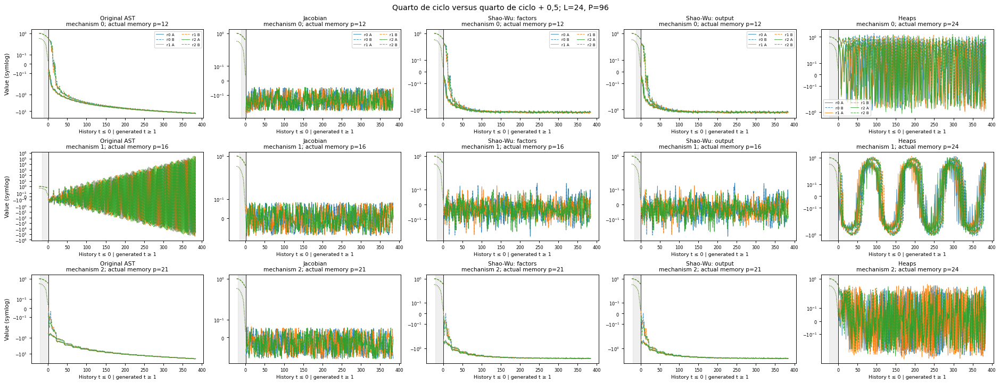

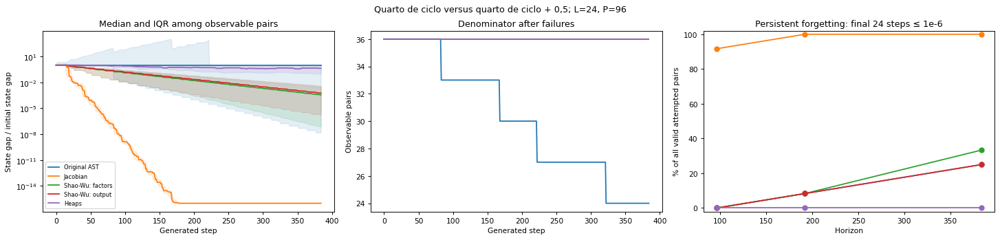

,block,method,case,horizon,mechanisms,pairs,pair_explosions,surviving_pairs,forgotten_pairs,median_final_state_gap,median_settling_step_achieved,weighted_checks,pair_explosion_pct,forgotten_pct_all_pairs,forgotten_pct_survivors
2,"Quarto de ciclo versus quarto de ciclo + 0,5; ...",Original AST,"Quarto de ciclo versus quarto de ciclo + 0,5; ...",384,12,36,12,24,9,0.500000,235.0,0,33.333333,25.000000,37.500000
5,"Quarto de ciclo versus quarto de ciclo + 0,5; ...",Jacobian,"Quarto de ciclo versus quarto de ciclo + 0,5; ...",384,12,36,0,36,36,0.000000,69.5,36,0.000000,100.000000,100.000000
8,"Quarto de ciclo versus quarto de ciclo + 0,5; ...",Shao-Wu: factors,"Quarto de ciclo versus quarto de ciclo + 0,5; ...",384,12,36,0,36,12,0.000174,238.5,0,0.000000,33.333333,33.333333
11,"Quarto de ciclo versus quarto de ciclo + 0,5; ...",Shao-Wu: output,"Quarto de ciclo versus quarto de ciclo + 0,5; ...",384,12,36,0,36,9,0.000287,217.0,0,0.000000,25.000000,25.000000
14,"Quarto de ciclo versus quarto de ciclo + 0,5; ...",Heaps,"Quarto de ciclo versus quarto de ciclo + 0,5; ...",384,12,36,0,36,0,0.213218,NaN,0,0.000000,0.000000,0.000000


In [25]:
result = show_pair('Quarto de ciclo versus quarto de ciclo + 0,5; L=24, P=96', HistorySpec('A', 'cosine', .5, 0.0, 96, 0.25), HistorySpec('B', 'cosine', .5, 0.5, 96, 0.25), cyclic_config(24))

**O que foi feito:** Avaliamos a influência do recorte ou da soma escalar mantendo a equação e a sequência futura de inovações. A faixa entre quartis descreve a dispersão das distâncias entre os pares ainda observáveis.

### Memória até 24; período 192

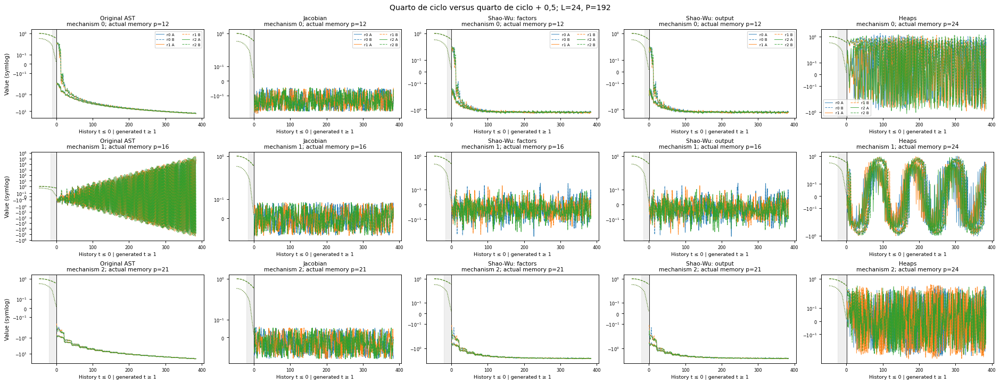

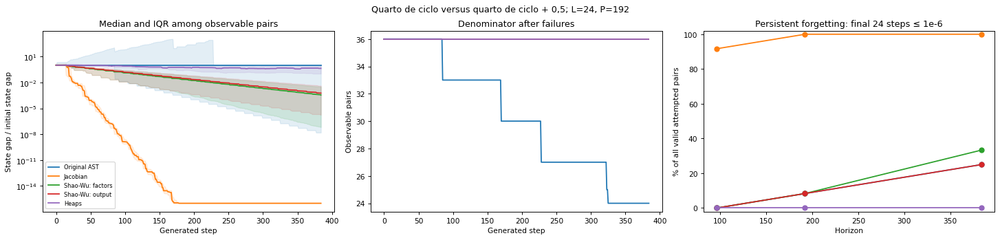

,block,method,case,horizon,mechanisms,pairs,pair_explosions,surviving_pairs,forgotten_pairs,median_final_state_gap,median_settling_step_achieved,weighted_checks,pair_explosion_pct,forgotten_pct_all_pairs,forgotten_pct_survivors
2,"Quarto de ciclo versus quarto de ciclo + 0,5; ...",Original AST,"Quarto de ciclo versus quarto de ciclo + 0,5; ...",384,12,36,12,24,9,0.500000,235.0,0,33.333333,25.000000,37.500000
5,"Quarto de ciclo versus quarto de ciclo + 0,5; ...",Jacobian,"Quarto de ciclo versus quarto de ciclo + 0,5; ...",384,12,36,0,36,36,0.000000,69.5,36,0.000000,100.000000,100.000000
8,"Quarto de ciclo versus quarto de ciclo + 0,5; ...",Shao-Wu: factors,"Quarto de ciclo versus quarto de ciclo + 0,5; ...",384,12,36,0,36,12,0.000174,238.5,0,0.000000,33.333333,33.333333
11,"Quarto de ciclo versus quarto de ciclo + 0,5; ...",Shao-Wu: output,"Quarto de ciclo versus quarto de ciclo + 0,5; ...",384,12,36,0,36,9,0.000287,217.0,0,0.000000,25.000000,25.000000
14,"Quarto de ciclo versus quarto de ciclo + 0,5; ...",Heaps,"Quarto de ciclo versus quarto de ciclo + 0,5; ...",384,12,36,0,36,0,0.213218,NaN,0,0.000000,0.000000,0.000000


In [26]:
result = show_pair('Quarto de ciclo versus quarto de ciclo + 0,5; L=24, P=192', HistorySpec('A', 'cosine', .5, 0.0, 192, 0.25), HistorySpec('B', 'cosine', .5, 0.5, 192, 0.25), cyclic_config(24))

**O que foi feito:** Avaliamos a influência do recorte ou da soma escalar mantendo a equação e a sequência futura de inovações. A faixa entre quartis descreve a dispersão das distâncias entre os pares ainda observáveis.

### Memória até 48; período 192

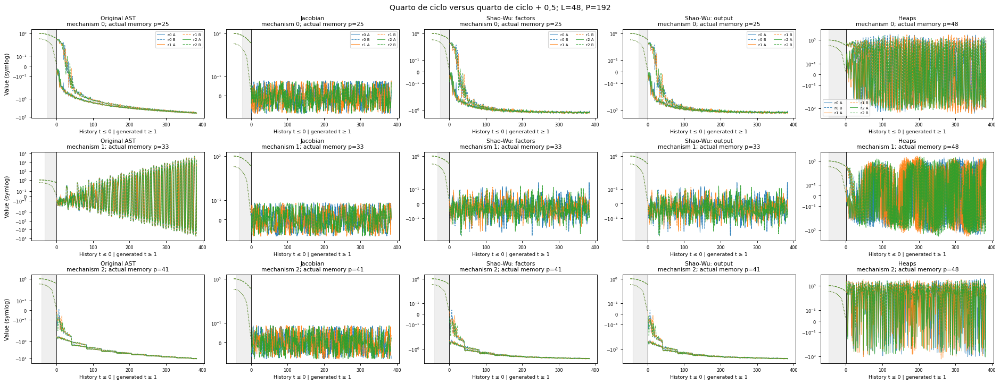

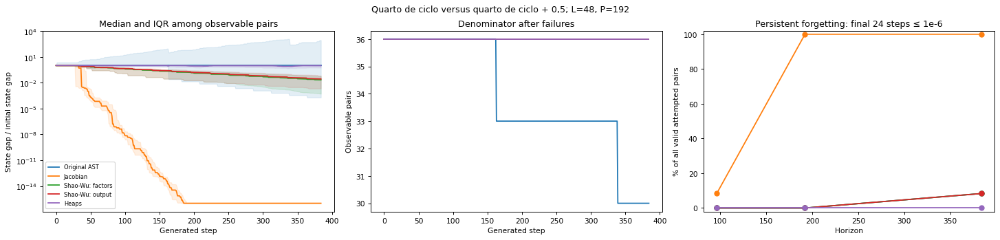

,block,method,case,horizon,mechanisms,pairs,pair_explosions,surviving_pairs,forgotten_pairs,median_final_state_gap,median_settling_step_achieved,weighted_checks,pair_explosion_pct,forgotten_pct_all_pairs,forgotten_pct_survivors
2,"Quarto de ciclo versus quarto de ciclo + 0,5; ...",Original AST,"Quarto de ciclo versus quarto de ciclo + 0,5; ...",384,12,36,6,30,3,0.500000,297.0,0,16.666667,8.333333,10.000000
5,"Quarto de ciclo versus quarto de ciclo + 0,5; ...",Jacobian,"Quarto de ciclo versus quarto de ciclo + 0,5; ...",384,12,36,0,36,36,0.000000,81.5,36,0.000000,100.000000,100.000000
8,"Quarto de ciclo versus quarto de ciclo + 0,5; ...",Shao-Wu: factors,"Quarto de ciclo versus quarto de ciclo + 0,5; ...",384,12,36,0,36,3,0.010767,270.0,0,0.000000,8.333333,8.333333
11,"Quarto de ciclo versus quarto de ciclo + 0,5; ...",Shao-Wu: output,"Quarto de ciclo versus quarto de ciclo + 0,5; ...",384,12,36,0,36,3,0.013747,270.0,0,0.000000,8.333333,8.333333
14,"Quarto de ciclo versus quarto de ciclo + 0,5; ...",Heaps,"Quarto de ciclo versus quarto de ciclo + 0,5; ...",384,12,36,0,36,0,0.481287,NaN,0,0.000000,0.000000,0.000000


In [27]:
result = show_pair('Quarto de ciclo versus quarto de ciclo + 0,5; L=48, P=192', HistorySpec('A', 'cosine', .5, 0.0, 192, 0.25), HistorySpec('B', 'cosine', .5, 0.5, 192, 0.25), cyclic_config(48))

**O que foi feito:** Avaliamos a influência do recorte ou da soma escalar mantendo a equação e a sequência futura de inovações. A faixa entre quartis descreve a dispersão das distâncias entre os pares ainda observáveis.

### Memória até 48; período 384

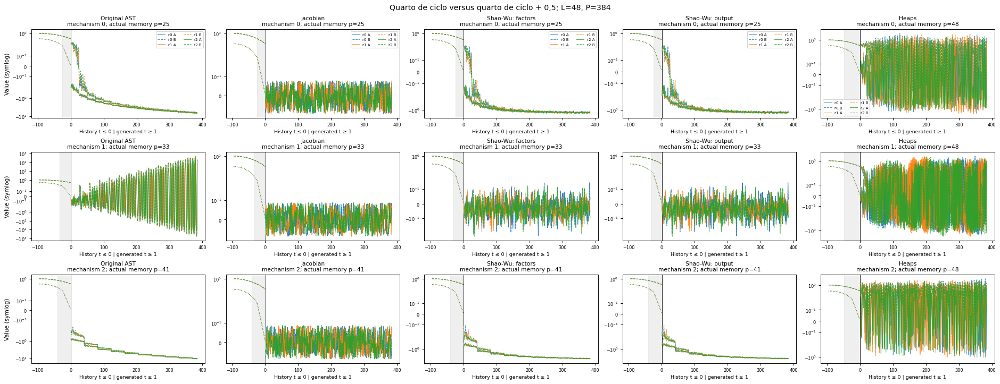

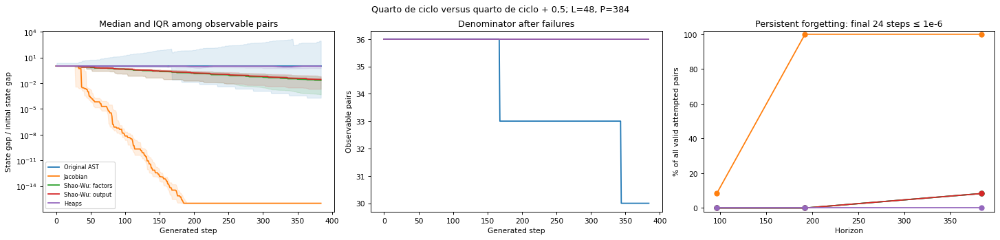

,block,method,case,horizon,mechanisms,pairs,pair_explosions,surviving_pairs,forgotten_pairs,median_final_state_gap,median_settling_step_achieved,weighted_checks,pair_explosion_pct,forgotten_pct_all_pairs,forgotten_pct_survivors
2,"Quarto de ciclo versus quarto de ciclo + 0,5; ...",Original AST,"Quarto de ciclo versus quarto de ciclo + 0,5; ...",384,12,36,6,30,3,0.500000,297.0,0,16.666667,8.333333,10.000000
5,"Quarto de ciclo versus quarto de ciclo + 0,5; ...",Jacobian,"Quarto de ciclo versus quarto de ciclo + 0,5; ...",384,12,36,0,36,36,0.000000,81.5,36,0.000000,100.000000,100.000000
8,"Quarto de ciclo versus quarto de ciclo + 0,5; ...",Shao-Wu: factors,"Quarto de ciclo versus quarto de ciclo + 0,5; ...",384,12,36,0,36,3,0.010767,270.0,0,0.000000,8.333333,8.333333
11,"Quarto de ciclo versus quarto de ciclo + 0,5; ...",Shao-Wu: output,"Quarto de ciclo versus quarto de ciclo + 0,5; ...",384,12,36,0,36,3,0.013747,270.0,0,0.000000,8.333333,8.333333
14,"Quarto de ciclo versus quarto de ciclo + 0,5; ...",Heaps,"Quarto de ciclo versus quarto de ciclo + 0,5; ...",384,12,36,0,36,0,0.481287,NaN,0,0.000000,0.000000,0.000000


In [28]:
result = show_pair('Quarto de ciclo versus quarto de ciclo + 0,5; L=48, P=384', HistorySpec('A', 'cosine', .5, 0.0, 384, 0.25), HistorySpec('B', 'cosine', .5, 0.5, 384, 0.25), cyclic_config(48))

**O que foi feito:** Avaliamos a influência do recorte ou da soma escalar mantendo a equação e a sequência futura de inovações. A faixa entre quartis descreve a dispersão das distâncias entre os pares ainda observáveis.

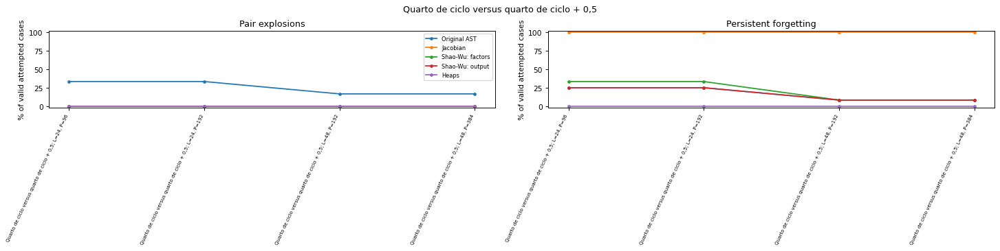

In [29]:
section_summary = pd.concat(SUMMARY_BLOCKS[-4:], ignore_index=True)
plot_condition_summary(section_summary, 'Quarto de ciclo versus quarto de ciclo + 0,5', forgetting=True)
plt.show()

**O que foi feito:** Comparamos os quatro pares de memória e período usando a taxa de explosões e a taxa de esquecimento entre todos os pares executados.

## Resultados consolidados: tabelas por horizonte

Cada linha conserva seu tipo de inicialização, método e tamanho de amostra. As condições não aplicáveis aparecem em tabela própria. Os tempos de simulação referem-se à chamada completa de até 384 passos, com parada na primeira explosão.

In [30]:
pd.set_option("display.max_rows", None)
FINAL_COLUMNS = ['block', 'method', 'pairs', 'pair_explosions', 'pair_explosion_pct', 'forgotten_pct_all_pairs', 'forgotten_pct_survivors', 'median_final_state_gap', 'median_settling_step_achieved']
SUMMARY = pd.concat(SUMMARY_BLOCKS, ignore_index=True)
SKIPPED = pd.concat(SKIPPED_BLOCKS, ignore_index=True) if SKIPPED_BLOCKS else pd.DataFrame()
for horizon in CONFIG.horizons:
    display(Markdown(f"### Horizonte {horizon}"))
    columns = FINAL_COLUMNS
    display(SUMMARY.loc[SUMMARY.horizon == horizon, columns].round(4))
display(Markdown("### Condições fora do domínio de aplicação"))
if SKIPPED.empty:
    display(Markdown("Todas as condições declaradas foram executadas."))
else:
    display(SKIPPED.groupby(["block", "method", "reason"], sort=False).skipped_trajectories.sum().reset_index())


### Horizonte 96

,block,method,pairs,pair_explosions,pair_explosion_pct,forgotten_pct_all_pairs,forgotten_pct_survivors,median_final_state_gap,median_settling_step_achieved
0,Constantes positiva e negativa,Original AST,96,27,28.1250,15.6250,21.7391,1.0000,23.0
3,Constantes positiva e negativa,Jacobian,96,0,0.0000,100.0000,100.0000,0.0000,56.0
6,Constantes positiva e negativa,Shao-Wu: factors,96,0,0.0000,25.0000,25.0000,0.0001,24.0
9,Constantes positiva e negativa,Shao-Wu: output,96,0,0.0000,25.0000,25.0000,0.0007,26.0
12,Constantes positiva e negativa,Heaps,96,0,0.0000,31.2500,31.2500,0.0070,28.5
15,Histórico uniforme versus zero,Original AST,96,30,31.2500,15.6250,22.7273,0.7629,22.0
18,Histórico uniforme versus zero,Jacobian,96,0,0.0000,100.0000,100.0000,0.0000,52.0
21,Histórico uniforme versus zero,Shao-Wu: factors,96,0,0.0000,28.1250,28.1250,0.0001,24.0
24,Histórico uniforme versus zero,Shao-Wu: output,96,0,0.0000,28.1250,28.1250,0.0005,26.0
27,Histórico uniforme versus zero,Heaps,96,0,0.0000,32.2917,32.2917,0.0080,30.0


### Horizonte 192

,block,method,pairs,pair_explosions,pair_explosion_pct,forgotten_pct_all_pairs,forgotten_pct_survivors,median_final_state_gap,median_settling_step_achieved
1,Constantes positiva e negativa,Original AST,96,48,50.0000,21.8750,43.7500,0.5247,30.0
4,Constantes positiva e negativa,Jacobian,96,0,0.0000,100.0000,100.0000,0.0000,56.0
7,Constantes positiva e negativa,Shao-Wu: factors,96,0,0.0000,53.1250,53.1250,0.0000,78.0
10,Constantes positiva e negativa,Shao-Wu: output,96,0,0.0000,50.0000,50.0000,0.0000,75.0
13,Constantes positiva e negativa,Heaps,96,0,0.0000,43.7500,43.7500,0.0001,42.5
16,Histórico uniforme versus zero,Original AST,96,47,48.9583,21.8750,42.8571,0.0147,26.0
19,Histórico uniforme versus zero,Jacobian,96,0,0.0000,100.0000,100.0000,0.0000,52.0
22,Histórico uniforme versus zero,Shao-Wu: factors,96,0,0.0000,53.1250,53.1250,0.0000,64.0
25,Histórico uniforme versus zero,Shao-Wu: output,96,0,0.0000,50.0000,50.0000,0.0000,61.0
28,Histórico uniforme versus zero,Heaps,96,0,0.0000,43.7500,43.7500,0.0001,39.5


### Horizonte 384

,block,method,pairs,pair_explosions,pair_explosion_pct,forgotten_pct_all_pairs,forgotten_pct_survivors,median_final_state_gap,median_settling_step_achieved
2,Constantes positiva e negativa,Original AST,96,48,50.0000,21.8750,43.7500,0.5011,30.0
5,Constantes positiva e negativa,Jacobian,96,0,0.0000,100.0000,100.0000,0.0000,56.0
8,Constantes positiva e negativa,Shao-Wu: factors,96,0,0.0000,75.0000,75.0000,0.0000,102.0
11,Constantes positiva e negativa,Shao-Wu: output,96,0,0.0000,71.8750,71.8750,0.0000,102.0
14,Constantes positiva e negativa,Heaps,96,0,0.0000,53.1250,53.1250,0.0000,63.0
17,Histórico uniforme versus zero,Original AST,96,47,48.9583,21.8750,42.8571,0.0005,26.0
20,Histórico uniforme versus zero,Jacobian,96,0,0.0000,100.0000,100.0000,0.0000,52.0
23,Histórico uniforme versus zero,Shao-Wu: factors,96,0,0.0000,81.2500,81.2500,0.0000,100.5
26,Histórico uniforme versus zero,Shao-Wu: output,96,0,0.0000,78.1250,78.1250,0.0000,99.0
29,Histórico uniforme versus zero,Heaps,96,0,0.0000,53.1250,53.1250,0.0000,55.0


### Condições fora do domínio de aplicação

,block,method,reason,skipped_trajectories
0,Histórico estacionário versus zero,Original AST,Joint stationary initializer unavailable,96
1,Histórico estacionário versus zero,Jacobian,Joint stationary initializer unavailable,96
2,Histórico estacionário versus zero,Shao-Wu: factors,Joint stationary initializer unavailable,96
3,Histórico estacionário versus zero,Shao-Wu: output,Joint stationary initializer unavailable,96


**O que foi feito:** Reunimos as métricas de todos os casos executados, sem somar grupos com condições diferentes. As exclusões indicam limitações de aplicação do método.

### Registro completo do experimento

Esta única célula reúne pergunta, hipótese, configurações, fórmulas, sementes, proveniência, métricas, síntese científica e comando de reprodução.

In [31]:
import os
def git_output(*args):
    return subprocess.check_output(["git", *args], cwd=ROOT, text=True).strip()

last = SUMMARY[SUMMARY.horizon == max(CONFIG.horizons)]
metrics = ["pair_explosion_pct", "forgotten_pct_all_pairs"] if STUDY == "forgetting" else [
    "explosions_pct", "near_zero_pct", "persistent_flat_pct"]
lines = []
for method, block in last.groupby("method", sort=False):
    values = "; ".join(f"{m}: {block[m].min():.2f}% a {block[m].max():.2f}%" for m in metrics)
    lines.append(f"- **{method}:** {values}.")
scientific_summary = "\n".join(lines) + (
    "\n\nOs intervalos acima são mínimos e máximos descritivos entre condições. "
    "Os resultados usam todos os casos executados, inclusive explosões; condições fora do domínio "
    "ficam listadas separadamente. Históricos cíclicos mudam o estado inicial, enquanto as equações "
    "determinam a continuação. A comparação de lags também reflete as diferentes construções "
    "dos mecanismos. Os padrões empíricos valem para as sementes, bancos e horizontes declarados."
)
source_hashes = {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest()
                 for p in sorted((ROOT / "src" / "tsfmxai").rglob("*.py"))}
record = {
    "research_question": QUESTION,
    "hypothesis": HYPOTHESIS,
    "design": "Cada seção é um tipo de inicialização; dentro dela comparamos as quatro famílias (cinco variantes).",
    "conditions": DECLARATIONS,
    "generator_banks": [{"configuration": asdict(c),
                         "generator_configurations": {g: asdict(v) for g, v in generator_configs(c).items()},
                         "formulas": {g: [m.formulas if hasattr(m, 'formulas') else [m.formula]
                                           for m in mechanisms] for g, mechanisms in banks.items()}}
                        for c, banks in BANKS.items()],
    "seeds": {"mechanism_root": CONFIG.mechanism_seed, "trajectory_root": CONFIG.trajectory_seed,
              "mechanisms": "derive_sample_seed(mechanism_root, index)",
              "streams": "SeedSequence([trajectory_root, mechanism_index, trajectory_index]).spawn(3)",
              "stream_names": ["unit_history", "future_innovations", "stationary_history"],
              "pairing": "Exact future innovation arrays reused across conditions within each mechanism/trajectory."},
    "provenance": {"source_sha256": source_hashes, "python": sys.version, "platform": platform.platform(),
                   "packages": {p: importlib.metadata.version(p) for p in ("numpy", "pandas", "matplotlib", "nbformat", "nbclient")},
                   "numerical_threads": 1, "execution_schedule": os.environ.get("TSFMXAI_EXECUTION_SCHEDULE", "Not specified by runner")},
    "metrics": json.loads(SUMMARY.to_json(orient="records")),
    "unsupported_cases": json.loads(SKIPPED.to_json(orient="records")),
    "scientific_summary": scientific_summary,
    "reproduction_command_from_repository_root": (
        ".venv/Scripts/python.exe -m jupyter nbconvert --to notebook --execute --inplace "
        f"experiments/time_series_initialization/{NOTEBOOK_NAME} --ExecutePreprocessor.timeout=3600"),
    "references": ["Heaps (2023): https://arxiv.org/pdf/2004.09455",
                   "Shao and Wu (2007), Theorem 5.1: https://arxiv.org/pdf/math/0611029",
                   "Project report, generator-specific guarantees and startup restrictions."],
}
display(Markdown("**Síntese científica desta execução**\n\n" + scientific_summary))
display(JSON(record, expanded=False))


**Síntese científica desta execução**

- **Original AST:** pair_explosion_pct: 16.67% a 50.00%; forgotten_pct_all_pairs: 8.33% a 25.00%.
- **Jacobian:** pair_explosion_pct: 0.00% a 0.00%; forgotten_pct_all_pairs: 100.00% a 100.00%.
- **Shao-Wu: factors:** pair_explosion_pct: 0.00% a 0.00%; forgotten_pct_all_pairs: 8.33% a 81.25%.
- **Shao-Wu: output:** pair_explosion_pct: 0.00% a 0.00%; forgotten_pct_all_pairs: 8.33% a 78.12%.
- **Heaps:** pair_explosion_pct: 0.00% a 0.00%; forgotten_pct_all_pairs: 0.00% a 59.38%.

Os intervalos acima são mínimos e máximos descritivos entre condições. Os resultados usam todos os casos executados, inclusive explosões; condições fora do domínio ficam listadas separadamente. Históricos cíclicos mudam o estado inicial, enquanto as equações determinam a continuação. A comparação de lags também reflete as diferentes construções dos mecanismos. Os padrões empíricos valem para as sementes, bancos e horizontes declarados.

<IPython.core.display.JSON object>

**O que foi feito:** O registro permite reproduzir a execução e recuperar as condições exatas que produziram cada linha da tabela. Todos os resultados ficam neste notebook.